# MSCAD regeneration pipeline -- one-notebook edition

Regenerates flow-level records **with flow identifiers** (Src/Dst IP, ports,
protocol, timestamp) from the six raw MSCAD PCAPs, verifies the extraction,
compares the result against the original Kaggle `MSCAD.csv`, and rebuilds the
two consolidated CSVs.

The published MSCAD distribution carries the 66 CICFlowMeter features and a
`Label`, but **no identifiers** -- so sequential pattern mining (PrefixSpan)
and attack-state-graph construction cannot be done from it at all. That is
what this pipeline supplies.

**Kernel -> Restart & Run All** reproduces everything. The notebook is
self-contained: the whole patched flow engine is inlined below, nothing is
imported from `scripts\`, and no cell depends on another cell having been run
out of order.

## Inputs

| What | Where |
|---|---|
| PCAPs (6 captures) | `...\MSCAD Dataset\PCAPs\pcapngtopcap` (fallback path tried automatically) |
| Original Kaggle CSV | `...\MSCAD\CSV_ORIGINAL` |
| Existing raw flow CSVs | `...\MSCAD_REGENERATED\raw\` |

## Outputs

| File | What |
|---|---|
| `raw\<capture>_flows.csv` | per-capture flows, identifiers + 66 features + Label |
| `MSCAD_consolidated.csv` | all captures, + `Label_Kaggle` + `Source_Capture`, sorted by Timestamp |
| `MSCAD_consolidated_ML.csv` | 66 features + Label, cleaned and de-duplicated |
| `metrics\*.json`, `metrics\*.csv` | every table below, machine-readable |
| `metrics\*.png` | the three figures |

## Runtime

| Step | With `RUN_EXTRACTION = False` | With `True` |
|---|---|---|
| 2 environment check | < 1 s | < 1 s |
| 4 extraction (PCAP -> flows) | skipped, reads `raw\` | **10-20 min** (two passes/capture) |
| 5 labelling from `raw\` | 5-20 s | 5-20 s |
| 6 verification | 10-40 s (+ tshark, if installed) | same |
| 7 comparison with Kaggle | 20-60 s | same |
| 8 plots | ~5 s | same |
| 9 final CSVs | 10-30 s | same |
| **total** | **about 1-3 min** | **about 12-25 min** |

> **Safety.** By default this notebook writes into
> `MSCAD_REGENERATED\notebook_test\` and leaves your current
> `MSCAD_consolidated.csv` untouched. Step 9b diffs the new files against the
> existing ones. Only once that diff is clean should you set
> `WRITE_TO_MAIN = True` in the settings cell.

> ### About the outputs saved in this file
>
> The cell outputs stored below come from an **automated smoke test on
> synthetic captures**, run on Linux to prove the notebook executes top to
> bottom with no errors. They are **not** your data:
>
> * the paths shown are the test harness's, not `D:\IDSPROJECT2026\...`;
> * the row counts (580 flows, a 341-row stand-in Kaggle file) are the
>   fixture's, not MSCAD's;
> * `tshark` was deliberately absent, so step 6 fell back to its own
>   independent packet counter.
>
> What the smoke test does establish: all 27 cells run clean, and the files
> the notebook produces are **byte-for-byte identical** to the ones the
> `scripts\` pipeline produces from the same input — verified both with
> `RUN_EXTRACTION = False` and with `True`.
>
> **Kernel → Restart & Run All** replaces every number below with yours.

---
## 1. Settings

Everything machine-specific lives in this one cell.

* `RUN_EXTRACTION` -- `False` reuses the existing `raw\*_flows.csv` (fast, and
  the normal case). `True` re-reads the PCAPs, which takes 10-20 minutes.
* `ONLY` -- set to a capture key (`"N-0"`) to process just that one.
* `ATTACKER_IP` -- manual override of the detected attacker IPs, per capture.
  A single string or a list both work. Anything not listed here is detected
  automatically with the >=50%-of-top-sender rule.
* `WRITE_TO_MAIN` -- `False` writes to `notebook_test\`; `True` writes to the
  project folder itself.

The `MSCAD_*` environment-variable overrides exist so this notebook can be
smoke-tested on another machine (and in CI) without editing the paths; on your
machine none of them are set, so the literal Windows paths below are used.

In [1]:
import os

# ----------------------------------------------------------------- switches
RUN_EXTRACTION = False     # True = re-run PCAP -> flow extraction (~10-20 min)
                           # False = reuse the existing raw\ CSVs
ONLY           = None      # e.g. "N-0" to process a single capture
ATTACKER_IP    = {}        # e.g. {"App-02": ["192.168.159.14", "192.168.159.10"]}
WRITE_TO_MAIN  = False     # False -> write into OUTPUT_DIR\notebook_test

# ----------------------------------------------------------------- paths
PROJECT_DIR = os.environ.get(
    "MSCAD_PROJECT_DIR",
    r"D:\IDSPROJECT2026\MSCAD\MSCAD_REGENERATED")

PCAP_DIR_CANDIDATES = [
    os.environ.get("MSCAD_PCAP_DIR") or
    r"D:\IDSPROJECT2026\MSCAD\MSCAD Dataset\PCAPs\pcapngtopcap",
    r"D:\IDSPROJECT2026\MSCAD\MSCAD Dataset\MSCAD Dataset\PCAPs\PCAPs\pcapngtopcap",
]
PCAP_SEARCH_ROOT = os.environ.get("MSCAD_SEARCH_ROOT",
                                  r"D:\IDSPROJECT2026\MSCAD")
CSV_ORIGINAL_DIR = os.environ.get("MSCAD_CSV_DIR",
                                  r"D:\IDSPROJECT2026\MSCAD\CSV_ORIGINAL")
TSHARK_EXE = os.environ.get("MSCAD_TSHARK",
                            r"C:\Program Files\Wireshark\tshark.exe")

# Where this run writes. Reading always happens from PROJECT_DIR.
OUTPUT_DIR = PROJECT_DIR if WRITE_TO_MAIN else os.path.join(PROJECT_DIR,
                                                            "notebook_test")
RAW_READ_DIR  = os.path.join(PROJECT_DIR, "raw")       # existing raw CSVs
RAW_WRITE_DIR = os.path.join(OUTPUT_DIR, "raw")
METRICS_DIR   = os.path.join(OUTPUT_DIR, "metrics")
LABELLED_DIR  = os.path.join(OUTPUT_DIR, "labelled")

for _d in (OUTPUT_DIR, RAW_WRITE_DIR, METRICS_DIR, LABELLED_DIR):
    os.makedirs(_d, exist_ok=True)

# When re-extracting, raw\ is written fresh into this run's folder and read
# back from there; otherwise we read the raw CSVs already in the project.
RAW_DIR = RAW_WRITE_DIR if RUN_EXTRACTION else RAW_READ_DIR

# ----------------------------------------------------------------- captures
# key, official label (dataset spelling, "Crwling" included), description
CAPTURES = [
    ("N-0",    "Normal",        "normal traffic"),
    ("Scan-1", "Port_Scan",     "Full / SYN / FIN / UDP port scans"),
    ("App-01", "DoS slowloris", "application-layer DDoS (HTTP Slowloris)"),
    ("App-02", "ICMP_Flood",    "volume-based DDoS (ICMP flood, fragmented pings)"),
    ("W-B-01", "Web_Crwling",   "web crawling"),
    ("W-B-02", "Brute_Force",   "password cracking"),
]
if ONLY:
    CAPTURES = [c for c in CAPTURES if c[0] == ONLY]
    if not CAPTURES:
        raise SystemExit("ONLY=%r matches no capture key" % ONLY)

BENIGN_LABEL   = "Benign"
PCAP_EXTENSIONS = [".pcap", ".pcapng", ".cap"]

# ----------------------------------------------- engine config (CFG namespace)
# The inlined engine reads these exactly as the scripts do, so the notebook
# and scripts\ cannot diverge.
from types import SimpleNamespace

CFG = SimpleNamespace(
    # timeouts (seconds)
    FLOW_TIMEOUT=120.0,      # Java CICFlowMeter default -- the Kaggle file's
    IDLE_TIMEOUT=240.0,
    ACTIVITY_TIMEOUT=5.0,
    CLUMP_TIMEOUT=1.0,
    BULK_BOUND=4,
    CLOSE_FLOW_ON_FIN=True,
    CLOSE_FLOW_ON_RST=False,
    SWEEP_EVERY_PACKETS=50_000,
    PROGRESS_EVERY_PACKETS=100_000,
    # semantics (Java-compatible, because Java produced MSCAD.csv)
    PKT_LEN_MODE="payload",   # L4 payload bytes, not whole frames
    HEADER_LEN_MODE="l4",     # TCP dataofs*4 / UDP 8
    STD_DDOF=1,               # commons-math (n-1), not numpy's n
    JAVA_INTEGER_DIVISION=True,
    SUBFLOW_MODE="divide",
    INIT_WIN_DEFAULT=-1,
    DROP_SINGLE_PACKET_FLOWS=False,
    ADD_FINAL_ACTIVE_SEGMENT=False,
    # labelling / output
    ATTACKER_SHARE=0.50,
    ATTACKER_TOP_N_PRINT=5,
    BENIGN_LABEL=BENIGN_LABEL,
    LABEL_COLUMN="Label",
    TIMESTAMP_FORMAT="%Y-%m-%d %H:%M:%S.%f",
    TIMESTAMP_UTC=True,
    IDENTIFIER_COLUMNS=["Src IP", "Dst IP", "Src Port", "Dst Port",
                        "Protocol", "Timestamp"],
    MATCH_KEY_FEATURES=[
        "Flow Duration", "Tot Fwd Pkts", "Tot Bwd Pkts", "TotLen Fwd Pkts",
        "TotLen Bwd Pkts", "Fwd Pkt Len Max", "Bwd Pkt Len Max",
        "Flow IAT Max", "Flow IAT Min", "Fwd Header Len", "Bwd Header Len",
        "Init Bwd Win Byts"],
    # Part 4 switches
    ML_INF_MODE="drop",            # "drop" as specified | "cap" keeps the rows
    ML_INF_CAP_FACTOR=10.0,
    ML_DROP_DUPLICATE_FEATURES=True,
)

LABEL_COLUMN = CFG.LABEL_COLUMN
IDENTIFIER_COLUMNS = CFG.IDENTIFIER_COLUMNS

print("project folder : %s" % PROJECT_DIR)
print("writing into   : %s%s" % (OUTPUT_DIR,
                                 "" if WRITE_TO_MAIN else "   (test mode)"))
print("reading raw\\   : %s" % RAW_DIR)
print("captures       : %s" % ", ".join(c[0] for c in CAPTURES))
print("RUN_EXTRACTION : %s" % RUN_EXTRACTION)
print("flow timeout %.0fs | idle %.0fs | activity %.0fs | clump %.0fs"
      % (CFG.FLOW_TIMEOUT, CFG.IDLE_TIMEOUT, CFG.ACTIVITY_TIMEOUT,
         CFG.CLUMP_TIMEOUT))
print("pkt-len %r | header-len %r | std ddof %d | subflow %r"
      % (CFG.PKT_LEN_MODE, CFG.HEADER_LEN_MODE, CFG.STD_DDOF,
         CFG.SUBFLOW_MODE))
print("time features in MICROSECONDS")
if ATTACKER_IP:
    print("manual attacker overrides: %s" % ATTACKER_IP)

project folder : /tmp/claude-0/-home-user-MSCAD2022/432fd689-59cc-55c9-96b0-ca4abc48ef75/scratchpad/final/out
writing into   : /tmp/claude-0/-home-user-MSCAD2022/432fd689-59cc-55c9-96b0-ca4abc48ef75/scratchpad/final/out/notebook_test   (test mode)
reading raw\   : /tmp/claude-0/-home-user-MSCAD2022/432fd689-59cc-55c9-96b0-ca4abc48ef75/scratchpad/final/out/raw
captures       : N-0, Scan-1, App-01, App-02, W-B-01, W-B-02
RUN_EXTRACTION : False
flow timeout 120s | idle 240s | activity 5s | clump 1s
pkt-len 'payload' | header-len 'l4' | std ddof 1 | subflow 'divide'
time features in MICROSECONDS


---
## 2. Environment check

Prints the interpreter and library versions, then checks the folders.

`cicflowmeter` is reported for the record but **never imported at runtime** --
the engine in step 3 is a reimplementation (see the note there), so a broken
`cicflowmeter` install cannot break this notebook. That is why a version other
than 0.5.0 is reported as a warning rather than stopping the run: nothing
downstream calls it. The install command is printed if it is missing or the
wrong version.

Hard requirements are `pandas`, `numpy`, `scipy` and `matplotlib`. `scapy` is
needed only for `.pcapng` input; `tshark` is optional, because step 6 carries
its own independent packet counter.

In [2]:
import importlib
import platform
import sys
import textwrap

INSTALL_HINT = textwrap.dedent("""
    %pip install -q scapy pandas numpy scipy requests
    %pip install -q --upgrade --no-deps --ignore-requires-python cicflowmeter==0.5.0
    then: Kernel -> Restart
""").strip()

print("Python     : %s" % sys.version.replace("\n", " "))
print("executable : %s" % sys.executable)
print("platform   : %s %s" % (platform.system(), platform.release()))
print()

REQUIRED = ["pandas", "numpy", "scipy", "matplotlib"]
OPTIONAL = ["scapy", "cicflowmeter"]
missing_required, versions = [], {}

for name in REQUIRED + OPTIONAL:
    try:
        mod = importlib.import_module(name)
        v = getattr(mod, "__version__", None)
        if v is None and name == "cicflowmeter":
            try:
                from importlib.metadata import version as _pv
                v = _pv("cicflowmeter")
            except Exception:
                v = "installed (version unknown)"
        versions[name] = v or "installed (version unknown)"
        print("%-14s %s" % (name, versions[name]))
    except Exception as exc:
        versions[name] = None
        mark = "REQUIRED" if name in REQUIRED else "optional"
        print("%-14s MISSING  (%s)  -- %s" % (name, mark, type(exc).__name__))
        if name in REQUIRED:
            missing_required.append(name)

if missing_required:
    raise SystemExit(
        "STOP: missing required package(s): %s\n\n%s"
        % (", ".join(missing_required), INSTALL_HINT))

cfm = versions.get("cicflowmeter")
print()
if cfm is None:
    print("NOTE: cicflowmeter is not installed. That is fine -- this notebook")
    print("      does not import it (see step 3). To install it anyway:")
    print(INSTALL_HINT)
elif not str(cfm).startswith("0.5.0"):
    print("WARNING: cicflowmeter %s found, 0.5.0 expected." % cfm)
    print("         Nothing here imports it, so the run is unaffected.")
    print("         To pin it:")
    print(INSTALL_HINT)
else:
    print("cicflowmeter 0.5.0 present (reference only; not imported).")

# ------------------------------------------------------------ folder checks
print("\n" + "-" * 70)
problems = []
if not os.path.isdir(PROJECT_DIR):
    problems.append("project folder not found: %s" % PROJECT_DIR)
else:
    print("OK  project folder   %s" % PROJECT_DIR)

if os.path.isdir(CSV_ORIGINAL_DIR):
    print("OK  CSV_ORIGINAL     %s" % CSV_ORIGINAL_DIR)
else:
    problems.append("CSV_ORIGINAL folder not found: %s" % CSV_ORIGINAL_DIR)


def resolve_pcap_dir(verbose=True):
    """First existing candidate, else a recursive search for pcapngtopcap."""
    for cand in PCAP_DIR_CANDIDATES:
        if cand and os.path.isdir(cand):
            return cand, "configured candidate"
    if os.path.isdir(PCAP_SEARCH_ROOT):
        hits = []
        for root, dirs, _files in os.walk(PCAP_SEARCH_ROOT):
            for d in dirs:
                if d.lower() == "pcapngtopcap":
                    hits.append(os.path.join(root, d))
        if hits:
            hits.sort(key=len)
            if verbose and len(hits) > 1:
                print("    several pcapngtopcap folders found:")
                for h in hits:
                    print("      %s" % h)
            return hits[0], "recursive search under %s" % PCAP_SEARCH_ROOT
    return None, "not found"


PCAP_DIR, PCAP_DIR_HOW = resolve_pcap_dir()
if PCAP_DIR:
    print("OK  PCAP folder      %s  (%s)" % (PCAP_DIR, PCAP_DIR_HOW))
else:
    msg = "PCAP folder not found (candidates: %s)" % "; ".join(
        c for c in PCAP_DIR_CANDIDATES if c)
    if RUN_EXTRACTION:
        problems.append(msg)
    else:
        print("--  PCAP folder      %s" % msg)
        print("    RUN_EXTRACTION is False, so the PCAPs are not needed;")
        print("    tshark verification in step 6 will be skipped.")

print("OK  tshark           %s" % TSHARK_EXE if os.path.isfile(TSHARK_EXE)
      else "--  tshark           not at %s (step 6 uses its own counter)"
      % TSHARK_EXE)

if problems:
    for p in problems:
        print("\nFATAL: %s" % p)
    raise SystemExit("STOP: fix the path(s) above in the settings cell.")
print("\nenvironment OK")

Python     : 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
executable : /usr/bin/python3
platform   : Linux 6.18.44-fc-v114



pandas         3.0.5
numpy          2.5.3
scipy          1.18.1
matplotlib     3.11.2
scapy          2.8.0
cicflowmeter   MISSING  (optional)  -- ModuleNotFoundError

NOTE: cicflowmeter is not installed. That is fine -- this notebook
      does not import it (see step 3). To install it anyway:
%pip install -q scapy pandas numpy scipy requests
%pip install -q --upgrade --no-deps --ignore-requires-python cicflowmeter==0.5.0
then: Kernel -> Restart

----------------------------------------------------------------------
OK  project folder   /tmp/claude-0/-home-user-MSCAD2022/432fd689-59cc-55c9-96b0-ca4abc48ef75/scratchpad/final/out
OK  CSV_ORIGINAL     /tmp/claude-0/-home-user-MSCAD2022/432fd689-59cc-55c9-96b0-ca4abc48ef75/scratchpad/final/csv_original
OK  PCAP folder      /tmp/claude-0/-home-user-MSCAD2022/432fd689-59cc-55c9-96b0-ca4abc48ef75/scratchpad/final/pcaps/pcapngtopcap  (configured candidate)
--  tshark           not at /nonexistent/tshark (step 6 uses its own counter)

environme

---
## 3. The patched CICFlowMeter engine (inlined)

### Why this is a reimplementation, not a patched import

`cicflowmeter` 0.5.0 defines the right 76 features, but its feature classes
take live scapy `Packet` objects and keep **every packet of a flow** in
`Flow.packets`. The three fixes this dataset needs -- include non-TCP/UDP
traffic, stop retaining packets, read real TCP flags -- change its *data
model*, not just its behaviour, so they cannot be applied as monkey-patches.
The code below therefore reimplements the same feature set while keeping the
package's own field names (`tot_fwd_pkts`, `flow_byts_s`, `cwr_flag_count`,
...), so the mapping to the MSCAD column names stays one-to-one and auditable.
The numeric definitions follow the **Java** CICFlowMeter, because that is the
tool that produced the Kaggle `MSCAD.csv`.

### Patches

| # | Problem in 0.5.0 | What is done here |
|---|---|---|
| 1 | CLI `-f file` crashes (`'bool' object has no attribute 'split'`) | no CLI; the engine is a library |
| 2 | every non-TCP/UDP packet silently dropped -- would lose the whole ICMP flood | **all IPv4** kept; ICMP and other protocols form `(src,dst,0,0,proto)` flows: Port 0, Protocol 1 |
| 3 | BPF filter needs tcpdump, absent on Windows | no capture filter is ever set |
| 4 | FIN read from the **IP** flags field | all eight flags read from the real TCP flags byte |
| 5 | first packet of each flow counted twice | each packet added exactly once |
| 6 | whole scapy packets retained -> big floods kill the kernel | nothing per-packet retained; Welford mean/variance + min/max/sum, so memory is O(open flows) |
| 7 | rescans every open flow after each FIN -> quadratic on brute force | timeouts checked on the packet's own flow, plus a sweep every 50,000 packets |
| 8 | timeouts | flow **120 s**, idle **240 s**, activity 5 s, clump 1 s |

Two further bugs found while reading the 0.5.0 source, also fixed:

9. `Flow.update_subflow` compares `packet.time` with `self.latest_timestamp`
   *after* that field was advanced to `packet.time`, so the difference is
   always 0, `update_active_idle` is never reached, and **every Active/Idle
   feature comes out identically 0**. `last_active` also starts at 0, so the
   first idle value would have been ~1.7e9 s.
10. `get_statistics` returns zeros unless `len(list) > 1`, so a two-packet
    flow (one IAT) reports **Flow IAT Mean/Max/Min = 0**.

### Units

Packet times are carried as **integer microseconds** end to end (a pcap record
gives seconds + microseconds, so this is exact and free of float drift). Flow
Duration, every IAT and every Active/Idle feature are emitted in
**microseconds**, matching MSCAD. Packet lengths come from the captured bytes;
packets are never rebuilt.

> This cell only defines classes and functions -- it reads no files and prints
> nothing.

In [3]:
# Feature-name tables: the 76 CICFlowMeter features and every alias.
# Taken verbatim from mscad_names.py.

import re

# --------------------------------------------------------------------------
# The 76 CICFlowMeter features, in canonical CSE-CIC-IDS2018 column order.
# (display name, internal key)
# --------------------------------------------------------------------------
CANONICAL_FEATURES = [
    ("Flow Duration",        "flow_duration"),
    ("Tot Fwd Pkts",         "tot_fwd_pkts"),
    ("Tot Bwd Pkts",         "tot_bwd_pkts"),
    ("TotLen Fwd Pkts",      "totlen_fwd_pkts"),
    ("TotLen Bwd Pkts",      "totlen_bwd_pkts"),
    ("Fwd Pkt Len Max",      "fwd_pkt_len_max"),
    ("Fwd Pkt Len Min",      "fwd_pkt_len_min"),
    ("Fwd Pkt Len Mean",     "fwd_pkt_len_mean"),
    ("Fwd Pkt Len Std",      "fwd_pkt_len_std"),
    ("Bwd Pkt Len Max",      "bwd_pkt_len_max"),
    ("Bwd Pkt Len Min",      "bwd_pkt_len_min"),
    ("Bwd Pkt Len Mean",     "bwd_pkt_len_mean"),
    ("Bwd Pkt Len Std",      "bwd_pkt_len_std"),
    ("Flow Byts/s",          "flow_byts_s"),
    ("Flow Pkts/s",          "flow_pkts_s"),
    ("Flow IAT Mean",        "flow_iat_mean"),
    ("Flow IAT Std",         "flow_iat_std"),
    ("Flow IAT Max",         "flow_iat_max"),
    ("Flow IAT Min",         "flow_iat_min"),
    ("Fwd IAT Tot",          "fwd_iat_tot"),
    ("Fwd IAT Mean",         "fwd_iat_mean"),
    ("Fwd IAT Std",          "fwd_iat_std"),
    ("Fwd IAT Max",          "fwd_iat_max"),
    ("Fwd IAT Min",          "fwd_iat_min"),
    ("Bwd IAT Tot",          "bwd_iat_tot"),
    ("Bwd IAT Mean",         "bwd_iat_mean"),
    ("Bwd IAT Std",          "bwd_iat_std"),
    ("Bwd IAT Max",          "bwd_iat_max"),
    ("Bwd IAT Min",          "bwd_iat_min"),
    ("Fwd PSH Flags",        "fwd_psh_flags"),
    ("Bwd PSH Flags",        "bwd_psh_flags"),
    ("Fwd URG Flags",        "fwd_urg_flags"),
    ("Bwd URG Flags",        "bwd_urg_flags"),
    ("Fwd Header Len",       "fwd_header_len"),
    ("Bwd Header Len",       "bwd_header_len"),
    ("Fwd Pkts/s",           "fwd_pkts_s"),
    ("Bwd Pkts/s",           "bwd_pkts_s"),
    ("Pkt Len Min",          "pkt_len_min"),
    ("Pkt Len Max",          "pkt_len_max"),
    ("Pkt Len Mean",         "pkt_len_mean"),
    ("Pkt Len Std",          "pkt_len_std"),
    ("Pkt Len Var",          "pkt_len_var"),
    ("FIN Flag Cnt",         "fin_flag_cnt"),
    ("SYN Flag Cnt",         "syn_flag_cnt"),
    ("RST Flag Cnt",         "rst_flag_cnt"),
    ("PSH Flag Cnt",         "psh_flag_cnt"),
    ("ACK Flag Cnt",         "ack_flag_cnt"),
    ("URG Flag Cnt",         "urg_flag_cnt"),
    ("CWE Flag Count",       "cwr_flag_count"),
    ("ECE Flag Cnt",         "ece_flag_cnt"),
    ("Down/Up Ratio",        "down_up_ratio"),
    ("Pkt Size Avg",         "pkt_size_avg"),
    ("Fwd Seg Size Avg",     "fwd_seg_size_avg"),
    ("Bwd Seg Size Avg",     "bwd_seg_size_avg"),
    ("Fwd Byts/b Avg",       "fwd_byts_b_avg"),
    ("Fwd Pkts/b Avg",       "fwd_pkts_b_avg"),
    ("Fwd Blk Rate Avg",     "fwd_blk_rate_avg"),
    ("Bwd Byts/b Avg",       "bwd_byts_b_avg"),
    ("Bwd Pkts/b Avg",       "bwd_pkts_b_avg"),
    ("Bwd Blk Rate Avg",     "bwd_blk_rate_avg"),
    ("Subflow Fwd Pkts",     "subflow_fwd_pkts"),
    ("Subflow Fwd Byts",     "subflow_fwd_byts"),
    ("Subflow Bwd Pkts",     "subflow_bwd_pkts"),
    ("Subflow Bwd Byts",     "subflow_bwd_byts"),
    ("Init Fwd Win Byts",    "init_fwd_win_byts"),
    ("Init Bwd Win Byts",    "init_bwd_win_byts"),
    ("Fwd Act Data Pkts",    "fwd_act_data_pkts"),
    ("Fwd Seg Size Min",     "fwd_seg_size_min"),
    ("Active Mean",          "active_mean"),
    ("Active Std",           "active_std"),
    ("Active Max",           "active_max"),
    ("Active Min",           "active_min"),
    ("Idle Mean",            "idle_mean"),
    ("Idle Std",             "idle_std"),
    ("Idle Max",             "idle_max"),
    ("Idle Min",             "idle_min"),
]

CANONICAL_DISPLAY = [d for d, _k in CANONICAL_FEATURES]
CANONICAL_KEYS = [k for _d, k in CANONICAL_FEATURES]

# --------------------------------------------------------------------------
# Alternate spellings (CICFlowMeter V3 / CIC-IDS2017 and common variants).
# --------------------------------------------------------------------------
ALIASES = {
    "flow_duration":      ["Flow Duration"],
    "tot_fwd_pkts":       ["Total Fwd Packets", "Total Fwd Pkts", "Tot Fwd Pkt"],
    "tot_bwd_pkts":       ["Total Backward Packets", "Total Bwd Packets", "Tot Bwd Pkt"],
    "totlen_fwd_pkts":    ["Total Length of Fwd Packets", "TotLen Fwd Pkt",
                           "Total Length of Fwd Packet"],
    "totlen_bwd_pkts":    ["Total Length of Bwd Packets", "TotLen Bwd Pkt",
                           "Total Length of Bwd Packet"],
    "fwd_pkt_len_max":    ["Fwd Packet Length Max"],
    "fwd_pkt_len_min":    ["Fwd Packet Length Min"],
    "fwd_pkt_len_mean":   ["Fwd Packet Length Mean"],
    "fwd_pkt_len_std":    ["Fwd Packet Length Std"],
    "bwd_pkt_len_max":    ["Bwd Packet Length Max"],
    "bwd_pkt_len_min":    ["Bwd Packet Length Min"],
    "bwd_pkt_len_mean":   ["Bwd Packet Length Mean"],
    "bwd_pkt_len_std":    ["Bwd Packet Length Std"],
    "flow_byts_s":        ["Flow Bytes/s", "Flow Byts/sec"],
    "flow_pkts_s":        ["Flow Packets/s", "Flow Pkts/sec"],
    "flow_iat_mean":      ["Flow IAT Mean"],
    "flow_iat_std":       ["Flow IAT Std"],
    "flow_iat_max":       ["Flow IAT Max"],
    "flow_iat_min":       ["Flow IAT Min"],
    "fwd_iat_tot":        ["Fwd IAT Total"],
    "bwd_iat_tot":        ["Bwd IAT Total"],
    "fwd_header_len":     ["Fwd Header Length"],
    "bwd_header_len":     ["Bwd Header Length"],
    "fwd_pkts_s":         ["Fwd Packets/s"],
    "bwd_pkts_s":         ["Bwd Packets/s"],
    "pkt_len_min":        ["Min Packet Length", "Packet Length Min"],
    "pkt_len_max":        ["Max Packet Length", "Packet Length Max"],
    "pkt_len_mean":       ["Packet Length Mean"],
    "pkt_len_std":        ["Packet Length Std"],
    "pkt_len_var":        ["Packet Length Variance", "Pkt Len Variance"],
    "fin_flag_cnt":       ["FIN Flag Count"],
    "syn_flag_cnt":       ["SYN Flag Count"],
    "rst_flag_cnt":       ["RST Flag Count"],
    "psh_flag_cnt":       ["PSH Flag Count"],
    "ack_flag_cnt":       ["ACK Flag Count"],
    "urg_flag_cnt":       ["URG Flag Count"],
    "cwr_flag_count":     ["CWE Flag Cnt", "CWR Flag Count", "CWR Flag Cnt",
                           "CWE Flag Count Count"],
    "ece_flag_cnt":       ["ECE Flag Count"],
    "pkt_size_avg":       ["Average Packet Size", "Avg Packet Size"],
    "fwd_seg_size_avg":   ["Avg Fwd Segment Size", "Fwd Segment Size Avg"],
    "bwd_seg_size_avg":   ["Avg Bwd Segment Size", "Bwd Segment Size Avg"],
    "fwd_byts_b_avg":     ["Fwd Avg Bytes/Bulk", "Fwd Bytes/Bulk Avg"],
    "fwd_pkts_b_avg":     ["Fwd Avg Packets/Bulk", "Fwd Packets/Bulk Avg"],
    "fwd_blk_rate_avg":   ["Fwd Avg Bulk Rate", "Fwd Bulk Rate Avg"],
    "bwd_byts_b_avg":     ["Bwd Avg Bytes/Bulk", "Bwd Bytes/Bulk Avg"],
    "bwd_pkts_b_avg":     ["Bwd Avg Packets/Bulk", "Bwd Packets/Bulk Avg"],
    "bwd_blk_rate_avg":   ["Bwd Avg Bulk Rate", "Bwd Bulk Rate Avg"],
    "subflow_fwd_pkts":   ["Subflow Fwd Packets"],
    "subflow_fwd_byts":   ["Subflow Fwd Bytes"],
    "subflow_bwd_pkts":   ["Subflow Bwd Packets"],
    "subflow_bwd_byts":   ["Subflow Bwd Bytes"],
    "init_fwd_win_byts":  ["Init_Win_bytes_forward", "Init Win bytes forward",
                           "Init Fwd Win Bytes"],
    "init_bwd_win_byts":  ["Init_Win_bytes_backward", "Init Win bytes backward",
                           "Init Bwd Win Bytes"],
    "fwd_act_data_pkts":  ["act_data_pkt_fwd", "Fwd Act Data Packets",
                           "Act Data Pkt Fwd"],
    "fwd_seg_size_min":   ["min_seg_size_forward", "Min Seg Size Forward",
                           "Fwd Seg Size Minimum"],
    "active_mean":        ["Active Mean"],
    "active_std":         ["Active Std"],
    "active_max":         ["Active Max"],
    "active_min":         ["Active Min"],
    "idle_mean":          ["Idle Mean"],
    "idle_std":           ["Idle Std"],
    "idle_max":           ["Idle Max"],
    "idle_min":           ["Idle Min"],
}

# Identifier / label columns that are not features.
IDENTIFIER_ALIASES = {
    "src_ip":    ["Src IP", "Source IP", "Src_IP"],
    "dst_ip":    ["Dst IP", "Destination IP", "Dst_IP"],
    "src_port":  ["Src Port", "Source Port", "Src_Port"],
    "dst_port":  ["Dst Port", "Destination Port", "Dst_Port"],
    "protocol":  ["Protocol"],
    "timestamp": ["Timestamp"],
    "flow_id":   ["Flow ID", "FlowID"],
    "label":     ["Label", "Labels", " Label"],
}


def normalise(name):
    """Canonical form for header matching: lowercase, alphanumerics only.

    Strips surrounding whitespace and quotes first, so ' "Flow Byts/s" '
    and 'Flow Byts/s' and 'flow_byts_s' all collapse together.
    """
    s = str(name).strip().strip('"').strip("'").strip()
    return re.sub(r"[^a-z0-9]", "", s.lower())


def _build_lookup():
    table = {}
    for display, key in CANONICAL_FEATURES:
        table[normalise(display)] = key
        table[normalise(key)] = key
    for key, alts in ALIASES.items():
        for alt in alts:
            table[normalise(alt)] = key
    for key, alts in IDENTIFIER_ALIASES.items():
        for alt in alts:
            table[normalise(alt)] = key
        table[normalise(key)] = key
    return table


NAME_TO_KEY = _build_lookup()

NON_FEATURE_KEYS = set(IDENTIFIER_ALIASES.keys())


def resolve_header(header):
    """Split an original CSV header into feature / identifier / unknown.

    Returns (feature_pairs, identifier_pairs, unknown_names) where
    feature_pairs is [(original_name, internal_key), ...] in the order the
    original file has them.
    """
    features, identifiers, unknown = [], [], []
    for raw in header:
        key = NAME_TO_KEY.get(normalise(raw))
        if key is None:
            unknown.append(raw)
        elif key in NON_FEATURE_KEYS:
            identifiers.append((raw, key))
        else:
            features.append((raw, key))
    return features, identifiers, unknown


# Features whose CICFlowMeter definition is integer-valued.  Used for the
# Part 3 row-matching key and for compact CSV formatting.
INTEGER_KEYS = {
    "flow_duration", "tot_fwd_pkts", "tot_bwd_pkts", "totlen_fwd_pkts",
    "totlen_bwd_pkts", "fwd_pkt_len_max", "fwd_pkt_len_min",
    "bwd_pkt_len_max", "bwd_pkt_len_min", "pkt_len_max", "pkt_len_min",
    "fwd_header_len", "bwd_header_len", "fwd_seg_size_min",
    "fwd_act_data_pkts", "flow_iat_max", "flow_iat_min", "fwd_iat_tot",
    "fwd_iat_max", "fwd_iat_min", "bwd_iat_tot", "bwd_iat_max",
    "bwd_iat_min", "fwd_psh_flags", "bwd_psh_flags", "fwd_urg_flags",
    "bwd_urg_flags", "fin_flag_cnt", "syn_flag_cnt", "rst_flag_cnt",
    "psh_flag_cnt", "ack_flag_cnt", "urg_flag_cnt", "ece_flag_cnt",
    "cwr_flag_count", "init_fwd_win_byts", "init_bwd_win_byts",
    "active_max", "active_min", "idle_max", "idle_min",
    "subflow_fwd_pkts", "subflow_bwd_pkts", "subflow_fwd_byts",
    "subflow_bwd_byts", "down_up_ratio",
}


# Expose the tables under the `N.` prefix the pipeline code uses.
N = SimpleNamespace(
    CANONICAL_FEATURES=CANONICAL_FEATURES,
    CANONICAL_DISPLAY=CANONICAL_DISPLAY,
    CANONICAL_KEYS=CANONICAL_KEYS,
    ALIASES=ALIASES,
    IDENTIFIER_ALIASES=IDENTIFIER_ALIASES,
    NAME_TO_KEY=NAME_TO_KEY,
    NON_FEATURE_KEYS=NON_FEATURE_KEYS,
    INTEGER_KEYS=INTEGER_KEYS,
    normalise=normalise,
    resolve_header=resolve_header,
)
print("feature tables ready: %d canonical features, %d name aliases"
      % (len(CANONICAL_FEATURES), len(NAME_TO_KEY)))

feature tables ready: 76 canonical features, 168 name aliases


In [4]:
# The flow/feature engine, verbatim from mscad_flowmeter.py.

import math
import os
import socket
import struct


# TCP flag bits
F_FIN, F_SYN, F_RST, F_PSH, F_ACK, F_URG, F_ECE, F_CWR = (
    0x01, 0x02, 0x04, 0x08, 0x10, 0x20, 0x40, 0x80)

FORWARD, REVERSE = 0, 1

US = 1_000_000  # microseconds per second


# ==========================================================================
# Incremental statistics
# ==========================================================================
class RunningStats:
    """Welford accumulator with min/max/sum. No sample list is retained."""

    __slots__ = ("n", "_mean", "_m2", "mn", "mx", "total")

    def __init__(self):
        self.n = 0
        self._mean = 0.0
        self._m2 = 0.0
        self.mn = None
        self.mx = None
        self.total = 0

    def add(self, x):
        self.n += 1
        self.total += x
        d = x - self._mean
        self._mean += d / self.n
        self._m2 += d * (x - self._mean)
        if self.mn is None or x < self.mn:
            self.mn = x
        if self.mx is None or x > self.mx:
            self.mx = x

    @property
    def mean(self):
        return self._mean if self.n else 0.0

    @property
    def var(self):
        """Variance. ddof from config: 1 = Java/commons-math, 0 = numpy."""
        if self.n == 0:
            return 0.0
        if CFG.STD_DDOF == 1:
            if self.n < 2:
                return 0.0
            return self._m2 / (self.n - 1)
        return self._m2 / self.n

    @property
    def std(self):
        v = self.var
        return math.sqrt(v) if v > 0 else 0.0

    @property
    def minimum(self):
        return self.mn if self.n else 0

    @property
    def maximum(self):
        return self.mx if self.n else 0


def _div(a, b):
    """Java-style division for the long/long features."""
    if b == 0:
        return 0
    if CFG.JAVA_INTEGER_DIVISION:
        return int(a) // int(b)
    return a / b


# ==========================================================================
# Packet reading
# ==========================================================================
class PcapFormatError(Exception):
    pass


# datalink type -> (fixed header length, ethertype offset or None)
_LINKTYPES = {
    1:   ("ether", 14),
    0:   ("null", 4),
    101: ("raw", 0),
    228: ("raw", 0),
    12:  ("raw", 0),
    113: ("sll", 16),
    276: ("sll2", 20),
}


def _l2_ipv4_offset(linkname, data, hdr_len):
    """Return the offset of the IPv4 header, or -1 if this is not IPv4."""
    if linkname == "raw":
        if len(data) >= 1 and (data[0] >> 4) == 4:
            return 0
        return -1
    if linkname == "ether":
        if len(data) < 14:
            return -1
        off = 12
        et = (data[12] << 8) | data[13]
        base = 14
        # Up to two stacked VLAN / QinQ tags.
        for _ in range(2):
            if et in (0x8100, 0x88A8, 0x9100):
                if len(data) < base + 4:
                    return -1
                et = (data[base + 2] << 8) | data[base + 3]
                base += 4
            else:
                break
        if et == 0x0800:
            return base
        return -1
    if linkname == "null":
        if len(data) < 4:
            return -1
        # BSD loopback: 32-bit address family, host byte order either way.
        fam_le = struct.unpack("<I", data[0:4])[0]
        fam_be = struct.unpack(">I", data[0:4])[0]
        if 2 in (fam_le, fam_be):
            return 4
        return -1
    if linkname == "sll":
        if len(data) < 16:
            return -1
        et = (data[14] << 8) | data[15]
        return 16 if et == 0x0800 else -1
    if linkname == "sll2":
        if len(data) < 20:
            return -1
        et = (data[0] << 8) | data[1]
        return 20 if et == 0x0800 else -1
    return -1


def iter_pcap_records(path, block=4 << 20):
    """Stream (t_us, caplen, origlen, data) out of a classic libpcap file.

    Hand-rolled on purpose: it is fast, it needs no scapy dissection, and it
    hands us the captured bytes directly (so packet lengths come from the
    capture, never from a rebuilt packet).  Yields the datalink name first.
    """
    with open(path, "rb") as fh:
        gh = fh.read(24)
        if len(gh) < 24:
            raise PcapFormatError("%s: file shorter than a pcap header" % path)
        magic = gh[:4]
        if magic == b"\xd4\xc3\xb2\xa1":
            endian, tsdiv = "<", 1          # usec, little endian
        elif magic == b"\xa1\xb2\xc3\xd4":
            endian, tsdiv = ">", 1
        elif magic == b"\x4d\x3c\xb2\xa1":
            endian, tsdiv = "<", 1000       # nsec resolution
        elif magic == b"\xa1\xb2\x3c\x4d":
            endian, tsdiv = ">", 1000
        elif magic[:4] == b"\x0a\x0d\x0d\x0a":
            raise PcapFormatError(
                "%s is a pcapng file; use the scapy fallback reader" % path)
        else:
            raise PcapFormatError(
                "%s: unrecognised pcap magic %r" % (path, magic))

        linktype = struct.unpack(endian + "I", gh[20:24])[0]
        if linktype not in _LINKTYPES:
            raise PcapFormatError(
                "%s: unsupported datalink type %d" % (path, linktype))
        linkname, _hdrlen = _LINKTYPES[linktype]
        yield linkname  # first item is the datalink name

        rec = struct.Struct(endian + "IIII")
        unpack = rec.unpack_from
        buf = bytearray()
        view_start = 0
        eof = False
        while True:
            # Top up the buffer.
            if not eof and len(buf) - view_start < (1 << 18):
                if view_start:
                    del buf[:view_start]
                    view_start = 0
                chunk = fh.read(block)
                if not chunk:
                    eof = True
                else:
                    buf += chunk
            avail = len(buf) - view_start
            if avail < 16:
                if eof:
                    break
                continue
            ts_sec, ts_frac, caplen, origlen = unpack(buf, view_start)
            if avail < 16 + caplen:
                if eof:
                    break  # truncated final record
                continue
            start = view_start + 16
            data = bytes(buf[start:start + caplen])
            view_start = start + caplen
            yield (ts_sec * US + ts_frac // tsdiv, caplen, origlen, data)


def iter_pcapng_records(path):
    """Fallback for .pcapng via scapy, same output shape as the above."""
    from scapy.utils import RawPcapNgReader

    rdr = RawPcapNgReader(path)
    linkname_sent = False
    for data, meta in rdr:
        lt = getattr(meta, "linktype", 1)
        if not linkname_sent:
            if lt not in _LINKTYPES:
                raise PcapFormatError(
                    "%s: unsupported datalink type %d" % (path, lt))
            yield _LINKTYPES[lt][0]
            linkname_sent = True
        tsresol = getattr(meta, "tsresol", 1_000_000) or 1_000_000
        raw_ts = (getattr(meta, "tshigh", 0) << 32) | getattr(meta, "tslow", 0)
        t_us = raw_ts * US // tsresol if tsresol != US else raw_ts
        wl = getattr(meta, "wirelen", len(data)) or len(data)
        yield (t_us, len(data), wl, bytes(data))
    if not linkname_sent:
        yield "ether"


def open_capture(path):
    gen = (iter_pcapng_records(path)
           if path.lower().endswith((".pcapng", ".ntar"))
           else iter_pcap_records(path))
    linkname = next(gen)
    return linkname, gen


class PacketCounters:
    __slots__ = ("total", "ipv4", "non_ipv4", "ipv4_truncated", "fragments",
                 "by_proto")

    def __init__(self):
        self.total = 0
        self.ipv4 = 0
        self.non_ipv4 = 0
        self.ipv4_truncated = 0
        self.fragments = 0
        self.by_proto = {}

    def as_dict(self):
        return {
            "packets_read": self.total,
            "ipv4_packets": self.ipv4,
            "non_ipv4_packets": self.non_ipv4,
            "ipv4_truncated_len": self.ipv4_truncated,
            "ipv4_non_first_fragments": self.fragments,
            "ipv4_by_protocol": dict(sorted(self.by_proto.items())),
        }


_inet_ntoa = socket.inet_ntoa


def parse_ipv4(data, off, caplen, counters):
    """Return a slim packet tuple, or None when this is not usable IPv4.

    (src, dst, sport, dport, proto, l4_hdr_len, payload_len, frame_len,
     tcp_flags, tcp_window, is_tcp)
    """
    avail = caplen - off
    if avail < 20:
        return None
    b0 = data[off]
    if (b0 >> 4) != 4:
        return None
    ihl = (b0 & 0x0F) * 4
    if ihl < 20 or avail < ihl:
        return None
    total_len = (data[off + 2] << 8) | data[off + 3]
    frag_word = (data[off + 6] << 8) | data[off + 7]
    frag_off = (frag_word & 0x1FFF) * 8
    proto = data[off + 9]
    src = _inet_ntoa(data[off + 12:off + 16])
    dst = _inet_ntoa(data[off + 16:off + 20])

    # Trust the IP total length when it is sane; fall back to the captured
    # bytes when the capture was snapped short or the NIC did TSO (len 0).
    if total_len == 0 or total_len > avail:
        counters.ipv4_truncated += 1
        ip_len = avail
    else:
        ip_len = total_len
    ip_payload_len = max(0, ip_len - ihl)

    counters.by_proto[proto] = counters.by_proto.get(proto, 0) + 1

    if frag_off > 0:
        # Non-first fragment: no transport header in this packet.
        counters.fragments += 1
        return (src, dst, 0, 0, proto, 0, ip_payload_len, caplen, 0, 0, False)

    l4 = off + ihl
    if proto == 6 and (caplen - l4) >= 20:
        sport = (data[l4] << 8) | data[l4 + 1]
        dport = (data[l4 + 2] << 8) | data[l4 + 3]
        dataofs = (data[l4 + 12] >> 4) * 4
        if dataofs < 20:
            dataofs = 20
        flags = data[l4 + 13]
        window = (data[l4 + 14] << 8) | data[l4 + 15]
        payload = max(0, ip_payload_len - dataofs)
        return (src, dst, sport, dport, 6, dataofs, payload, caplen,
                flags, window, True)
    if proto == 17 and (caplen - l4) >= 8:
        sport = (data[l4] << 8) | data[l4 + 1]
        dport = (data[l4 + 2] << 8) | data[l4 + 3]
        udp_len = (data[l4 + 4] << 8) | data[l4 + 5]
        payload = (max(0, udp_len - 8) if 8 <= udp_len <= ip_payload_len
                   else max(0, ip_payload_len - 8))
        return (src, dst, sport, dport, 17, 8, payload, caplen, 0, 0, False)
    if proto == 1 and (caplen - l4) >= 8:
        # ICMP: 8-byte header, no ports.  Patch 2 keeps these.
        return (src, dst, 0, 0, 1, 8, max(0, ip_payload_len - 8), caplen,
                0, 0, False)
    # Any other IP protocol, or a transport header too short to read.
    return (src, dst, 0, 0, proto, 0, ip_payload_len, caplen, 0, 0, False)


# ==========================================================================
# Flow
# ==========================================================================
class Flow:
    """One CICFlowMeter flow, maintained incrementally (patch 6)."""

    __slots__ = (
        "src_ip", "dst_ip", "src_port", "dst_port", "protocol",
        "start_t", "last_t", "last_fwd_t", "last_bwd_t",
        "fwd_len", "bwd_len", "all_len",
        "flow_iat", "fwd_iat", "bwd_iat",
        "fwd_hdr_bytes", "bwd_hdr_bytes", "min_seg_fwd",
        "fwd_act_data_pkts",
        "fin", "syn", "rst", "psh", "ack", "urg", "ece", "cwr",
        "fwd_psh", "bwd_psh", "fwd_urg", "bwd_urg",
        "init_fwd_win", "init_bwd_win",
        "start_active", "end_active", "active", "idle",
        "sf_last_t", "sf_count",
        "fb_last_t", "fb_start_tmp", "fb_count", "fb_count_tmp",
        "fb_duration", "fb_pkt_count", "fb_size", "fb_size_tmp",
        "bb_last_t", "bb_start_tmp", "bb_count", "bb_count_tmp",
        "bb_duration", "bb_pkt_count", "bb_size", "bb_size_tmp",
    )

    def __init__(self, pkt, t_us, direction):
        src, dst, sport, dport, proto = pkt[0], pkt[1], pkt[2], pkt[3], pkt[4]
        if direction == FORWARD:
            self.src_ip, self.dst_ip = src, dst
            self.src_port, self.dst_port = sport, dport
        else:
            self.src_ip, self.dst_ip = dst, src
            self.src_port, self.dst_port = dport, sport
        self.protocol = proto

        self.start_t = t_us
        self.last_t = t_us
        self.last_fwd_t = 0
        self.last_bwd_t = 0

        self.fwd_len = RunningStats()
        self.bwd_len = RunningStats()
        self.all_len = RunningStats()
        self.flow_iat = RunningStats()
        self.fwd_iat = RunningStats()
        self.bwd_iat = RunningStats()

        self.fwd_hdr_bytes = 0
        self.bwd_hdr_bytes = 0
        self.min_seg_fwd = None
        self.fwd_act_data_pkts = 0

        self.fin = self.syn = self.rst = self.psh = 0
        self.ack = self.urg = self.ece = self.cwr = 0
        self.fwd_psh = self.bwd_psh = self.fwd_urg = self.bwd_urg = 0

        self.init_fwd_win = CFG.INIT_WIN_DEFAULT
        self.init_bwd_win = CFG.INIT_WIN_DEFAULT

        # Java seeds both active markers with the flow's first packet time,
        # which is what makes the first idle value sane (patch 9).
        self.start_active = t_us
        self.end_active = t_us
        self.active = RunningStats()
        self.idle = RunningStats()

        self.sf_last_t = t_us
        self.sf_count = 0

        self.fb_last_t = self.fb_start_tmp = 0
        self.fb_count = self.fb_count_tmp = 0
        self.fb_duration = self.fb_pkt_count = 0
        self.fb_size = self.fb_size_tmp = 0
        self.bb_last_t = self.bb_start_tmp = 0
        self.bb_count = self.bb_count_tmp = 0
        self.bb_duration = self.bb_pkt_count = 0
        self.bb_size = self.bb_size_tmp = 0

    # -- packet ingestion -------------------------------------------------
    def add_packet(self, pkt, t_us, direction):
        (_src, _dst, _sp, _dp, _proto, l4_hdr, payload, frame,
         flags, window, is_tcp) = pkt

        length = payload if CFG.PKT_LEN_MODE == "payload" else frame
        hdr = l4_hdr if CFG.HEADER_LEN_MODE == "l4" else 0

        npkts = self.fwd_len.n + self.bwd_len.n
        if npkts:  # not the first packet of the flow (patch 5)
            self._update_active_idle(t_us)
            self._update_subflow(t_us)
            self.flow_iat.add(t_us - self.last_t)

        self._update_bulk(t_us, payload, direction)

        if is_tcp:
            if flags & F_FIN:
                self.fin += 1
            if flags & F_SYN:
                self.syn += 1
            if flags & F_RST:
                self.rst += 1
            if flags & F_PSH:
                self.psh += 1
            if flags & F_ACK:
                self.ack += 1
            if flags & F_URG:
                self.urg += 1
            if flags & F_ECE:
                self.ece += 1
            if flags & F_CWR:
                self.cwr += 1

        if direction == FORWARD:
            if self.fwd_len.n:
                self.fwd_iat.add(t_us - self.last_fwd_t)
            elif is_tcp:
                self.init_fwd_win = window
            self.fwd_len.add(length)
            self.fwd_hdr_bytes += hdr
            if self.min_seg_fwd is None or l4_hdr < self.min_seg_fwd:
                self.min_seg_fwd = l4_hdr
            if payload >= 1:
                self.fwd_act_data_pkts += 1
            if is_tcp:
                if flags & F_PSH:
                    self.fwd_psh += 1
                if flags & F_URG:
                    self.fwd_urg += 1
            self.last_fwd_t = t_us
        else:
            if self.bwd_len.n:
                self.bwd_iat.add(t_us - self.last_bwd_t)
            elif is_tcp:
                self.init_bwd_win = window
            self.bwd_len.add(length)
            self.bwd_hdr_bytes += hdr
            if payload >= 1:
                pass  # Java tracks act_data_pkt for the forward side only
            if is_tcp:
                if flags & F_PSH:
                    self.bwd_psh += 1
                if flags & F_URG:
                    self.bwd_urg += 1
            self.last_bwd_t = t_us

        self.all_len.add(length)
        self.last_t = t_us

    def _update_active_idle(self, t_us):
        """Java BasicFlow.updateActiveIdleTime, called once per packet.

        The Java tool reaches this from two places and passes a duration in
        one of them; we call it once with the real timestamp (patch 9).
        """
        thr = int(CFG.ACTIVITY_TIMEOUT * US)
        if (t_us - self.end_active) > thr:
            dur = self.end_active - self.start_active
            if dur > 0:
                self.active.add(dur)
            self.idle.add(t_us - self.end_active)
            self.start_active = t_us
            self.end_active = t_us
        else:
            self.end_active = t_us

    def _update_subflow(self, t_us):
        if (t_us - self.sf_last_t) > int(CFG.CLUMP_TIMEOUT * US):
            self.sf_count += 1
        self.sf_last_t = t_us

    def _update_bulk(self, t_us, payload, direction):
        if payload <= 0:
            return
        clump = int(CFG.CLUMP_TIMEOUT * US)
        if direction == FORWARD:
            if self.bb_last_t > self.fb_start_tmp:
                self.fb_start_tmp = 0
            if self.fb_start_tmp == 0:
                self.fb_start_tmp = t_us
                self.fb_last_t = t_us
                self.fb_count_tmp = 1
                self.fb_size_tmp = payload
            elif (t_us - self.fb_last_t) > clump:
                self.fb_start_tmp = t_us
                self.fb_last_t = t_us
                self.fb_count_tmp = 1
                self.fb_size_tmp = payload
            else:
                self.fb_count_tmp += 1
                self.fb_size_tmp += payload
                if self.fb_count_tmp == CFG.BULK_BOUND:
                    self.fb_count += 1
                    self.fb_pkt_count += self.fb_count_tmp
                    self.fb_size += self.fb_size_tmp
                    self.fb_duration += t_us - self.fb_start_tmp
                elif self.fb_count_tmp > CFG.BULK_BOUND:
                    self.fb_pkt_count += 1
                    self.fb_size += payload
                    self.fb_duration += t_us - self.fb_last_t
                self.fb_last_t = t_us
        else:
            if self.fb_last_t > self.bb_start_tmp:
                self.bb_start_tmp = 0
            if self.bb_start_tmp == 0:
                self.bb_start_tmp = t_us
                self.bb_last_t = t_us
                self.bb_count_tmp = 1
                self.bb_size_tmp = payload
            elif (t_us - self.bb_last_t) > clump:
                self.bb_start_tmp = t_us
                self.bb_last_t = t_us
                self.bb_count_tmp = 1
                self.bb_size_tmp = payload
            else:
                self.bb_count_tmp += 1
                self.bb_size_tmp += payload
                if self.bb_count_tmp == CFG.BULK_BOUND:
                    self.bb_count += 1
                    self.bb_pkt_count += self.bb_count_tmp
                    self.bb_size += self.bb_size_tmp
                    self.bb_duration += t_us - self.bb_start_tmp
                elif self.bb_count_tmp > CFG.BULK_BOUND:
                    self.bb_pkt_count += 1
                    self.bb_size += payload
                    self.bb_duration += t_us - self.bb_last_t
                self.bb_last_t = t_us

    # -- output -----------------------------------------------------------
    @property
    def packet_count(self):
        return self.fwd_len.n + self.bwd_len.n

    @property
    def duration_us(self):
        return self.last_t - self.start_t

    def get_data(self):
        """All 76 CICFlowMeter features under the pip-cicflowmeter key names."""
        if CFG.ADD_FINAL_ACTIVE_SEGMENT:
            tail = self.end_active - self.start_active
            if tail > 0:
                self.active.add(tail)

        dur = self.duration_us
        dur_s = dur / float(US)
        n_fwd, n_bwd = self.fwd_len.n, self.bwd_len.n
        n_tot = n_fwd + n_bwd
        byts = self.fwd_len.total + self.bwd_len.total

        if dur > 0:
            flow_byts_s = byts / dur_s
            flow_pkts_s = n_tot / dur_s
            fwd_pkts_s = n_fwd / dur_s
            bwd_pkts_s = n_bwd / dur_s
        else:
            # Zero-duration flow.  The Java tool divides by 0.0 and so writes
            # Infinity (or NaN when the numerator is 0 too).  We always emit
            # Infinity, so that any NaN in the output is a genuine bug and the
            # Part 2 NaN check stays meaningful.  02_verify.py reports the
            # zero-duration flow count separately.
            inf = float("inf")
            flow_byts_s = flow_pkts_s = fwd_pkts_s = bwd_pkts_s = inf

        sf = self.sf_count if CFG.SUBFLOW_MODE == "divide" else 0
        if CFG.SUBFLOW_MODE == "divide":
            sf_div = sf + 1  # 1 subflow plus one per >1 s gap
            sub_fwd_pkts = _div(n_fwd, sf_div)
            sub_bwd_pkts = _div(n_bwd, sf_div)
            sub_fwd_byts = _div(self.fwd_len.total, sf_div)
            sub_bwd_byts = _div(self.bwd_len.total, sf_div)
        else:
            sub_fwd_pkts, sub_bwd_pkts = n_fwd, n_bwd
            sub_fwd_byts, sub_bwd_byts = self.fwd_len.total, self.bwd_len.total

        fb_rate = (self.fb_size / (self.fb_duration / float(US))
                   if self.fb_duration > 0 else 0)
        bb_rate = (self.bb_size / (self.bb_duration / float(US))
                   if self.bb_duration > 0 else 0)

        fwd_mean = self.fwd_len.mean
        bwd_mean = self.bwd_len.mean

        return {
            "src_ip": self.src_ip,
            "dst_ip": self.dst_ip,
            "src_port": self.src_port,
            "dst_port": self.dst_port,
            "protocol": self.protocol,
            "timestamp": self.start_t,          # integer microseconds
            "flow_duration": dur,
            "tot_fwd_pkts": n_fwd,
            "tot_bwd_pkts": n_bwd,
            "totlen_fwd_pkts": self.fwd_len.total,
            "totlen_bwd_pkts": self.bwd_len.total,
            "fwd_pkt_len_max": self.fwd_len.maximum,
            "fwd_pkt_len_min": self.fwd_len.minimum,
            "fwd_pkt_len_mean": fwd_mean,
            "fwd_pkt_len_std": self.fwd_len.std,
            "bwd_pkt_len_max": self.bwd_len.maximum,
            "bwd_pkt_len_min": self.bwd_len.minimum,
            "bwd_pkt_len_mean": bwd_mean,
            "bwd_pkt_len_std": self.bwd_len.std,
            "flow_byts_s": flow_byts_s,
            "flow_pkts_s": flow_pkts_s,
            "flow_iat_mean": self.flow_iat.mean,
            "flow_iat_std": self.flow_iat.std,
            "flow_iat_max": self.flow_iat.maximum,
            "flow_iat_min": self.flow_iat.minimum,
            "fwd_iat_tot": self.fwd_iat.total,
            "fwd_iat_mean": self.fwd_iat.mean,
            "fwd_iat_std": self.fwd_iat.std,
            "fwd_iat_max": self.fwd_iat.maximum,
            "fwd_iat_min": self.fwd_iat.minimum,
            "bwd_iat_tot": self.bwd_iat.total,
            "bwd_iat_mean": self.bwd_iat.mean,
            "bwd_iat_std": self.bwd_iat.std,
            "bwd_iat_max": self.bwd_iat.maximum,
            "bwd_iat_min": self.bwd_iat.minimum,
            "fwd_psh_flags": self.fwd_psh,
            "bwd_psh_flags": self.bwd_psh,
            "fwd_urg_flags": self.fwd_urg,
            "bwd_urg_flags": self.bwd_urg,
            "fwd_header_len": self.fwd_hdr_bytes,
            "bwd_header_len": self.bwd_hdr_bytes,
            "fwd_pkts_s": fwd_pkts_s,
            "bwd_pkts_s": bwd_pkts_s,
            "pkt_len_min": self.all_len.minimum,
            "pkt_len_max": self.all_len.maximum,
            "pkt_len_mean": self.all_len.mean,
            "pkt_len_std": self.all_len.std,
            "pkt_len_var": self.all_len.var,
            "fin_flag_cnt": self.fin,
            "syn_flag_cnt": self.syn,
            "rst_flag_cnt": self.rst,
            "psh_flag_cnt": self.psh,
            "ack_flag_cnt": self.ack,
            "urg_flag_cnt": self.urg,
            "cwr_flag_count": self.cwr,     # real CWR bit, not Fwd URG
            "ece_flag_cnt": self.ece,
            "down_up_ratio": _div(n_bwd, n_fwd) if n_fwd else 0,
            "pkt_size_avg": (byts / n_tot) if n_tot else 0,
            "fwd_seg_size_avg": fwd_mean,
            "bwd_seg_size_avg": bwd_mean,
            "fwd_byts_b_avg": _div(self.fb_size, self.fb_count),
            "fwd_pkts_b_avg": _div(self.fb_pkt_count, self.fb_count),
            "fwd_blk_rate_avg": fb_rate,
            "bwd_byts_b_avg": _div(self.bb_size, self.bb_count),
            "bwd_pkts_b_avg": _div(self.bb_pkt_count, self.bb_count),
            "bwd_blk_rate_avg": bb_rate,
            "subflow_fwd_pkts": sub_fwd_pkts,
            "subflow_fwd_byts": sub_fwd_byts,
            "subflow_bwd_pkts": sub_bwd_pkts,
            "subflow_bwd_byts": sub_bwd_byts,
            "init_fwd_win_byts": self.init_fwd_win,
            "init_bwd_win_byts": self.init_bwd_win,
            "fwd_act_data_pkts": self.fwd_act_data_pkts,
            "fwd_seg_size_min": (self.min_seg_fwd
                                 if self.min_seg_fwd is not None else 0),
            "active_mean": self.active.mean,
            "active_std": self.active.std,
            "active_max": self.active.maximum,
            "active_min": self.active.minimum,
            "idle_mean": self.idle.mean,
            "idle_std": self.idle.std,
            "idle_max": self.idle.maximum,
            "idle_min": self.idle.minimum,
        }


# ==========================================================================
# Engine
# ==========================================================================
class FlowEngine:
    """Builds flows from a capture and hands each finished flow to a sink."""

    def __init__(self, sink, progress=None):
        self.flows = {}
        self.sink = sink
        self.progress = progress
        self.counters = PacketCounters()
        self.flows_written = 0
        self.single_packet_flows = 0
        self.zero_duration_flows = 0
        self.flows_dropped_single = 0
        self.last_packet_time_us = 0

    def _emit(self, flow):
        if (CFG.DROP_SINGLE_PACKET_FLOWS and flow.packet_count <= 1):
            self.flows_dropped_single += 1
            return
        if flow.packet_count <= 1:
            self.single_packet_flows += 1
        if flow.duration_us == 0:
            self.zero_duration_flows += 1
        self.sink(flow.get_data())
        self.flows_written += 1

    def run(self, path):
        linkname, records = open_capture(path)
        c = self.counters
        flows = self.flows
        flow_to = int(CFG.FLOW_TIMEOUT * US)
        idle_to = int(CFG.IDLE_TIMEOUT * US)
        sweep_every = CFG.SWEEP_EVERY_PACKETS
        prog_every = CFG.PROGRESS_EVERY_PACKETS
        last_t_us = 0

        for t_us, caplen, origlen, data in records:
            c.total += 1
            if prog_every and self.progress and c.total % prog_every == 0:
                self.progress(c.total, len(flows), self.flows_written)

            off = _l2_ipv4_offset(linkname, data, caplen)
            if off < 0:
                c.non_ipv4 += 1
                continue
            pkt = parse_ipv4(data, off, caplen, c)
            if pkt is None:
                c.non_ipv4 += 1
                continue
            c.ipv4 += 1
            last_t_us = t_us

            src, dst, sp, dp, proto = pkt[0], pkt[1], pkt[2], pkt[3], pkt[4]
            fkey = (src, dst, sp, dp, proto)
            flow = flows.get(fkey)
            direction = FORWARD
            if flow is None:
                rkey = (dst, src, dp, sp, proto)
                flow = flows.get(rkey)
                if flow is not None:
                    fkey = rkey
                    direction = REVERSE

            if flow is None:
                flows[fkey] = Flow(pkt, t_us, FORWARD)
                flows[fkey].add_packet(pkt, t_us, FORWARD)
                continue

            # Patch 7: timeouts are checked on this flow only.
            if ((t_us - flow.start_t) > flow_to
                    or (t_us - flow.last_t) > idle_to):
                del flows[fkey]
                self._emit(flow)
                nkey = (src, dst, sp, dp, proto)
                flows[nkey] = Flow(pkt, t_us, FORWARD)
                flows[nkey].add_packet(pkt, t_us, FORWARD)
                continue

            flow.add_packet(pkt, t_us, direction)

            # Patch 4: real TCP flags.  Patch 7: no full rescan here.
            tcp_flags = pkt[8]
            if pkt[10] and ((CFG.CLOSE_FLOW_ON_FIN and (tcp_flags & F_FIN))
                            or (CFG.CLOSE_FLOW_ON_RST and (tcp_flags & F_RST))):
                del flows[fkey]
                self._emit(flow)
                continue

            if sweep_every and c.total % sweep_every == 0:
                self._sweep(t_us, flow_to, idle_to)

        # Flush everything still open.
        for flow in list(flows.values()):
            self._emit(flow)
        flows.clear()
        self.last_packet_time_us = last_t_us
        return self.counters

    def _sweep(self, now_us, flow_to, idle_to):
        dead = [k for k, f in self.flows.items()
                if (now_us - f.start_t) > flow_to
                or (now_us - f.last_t) > idle_to]
        for k in dead:
            f = self.flows.pop(k)
            self._emit(f)


print("engine ready: RunningStats, Flow, FlowEngine, %d-feature get_data()"
      % len(CANONICAL_FEATURES))

engine ready: RunningStats, Flow, FlowEngine, 76-feature get_data()


---
## 3b. Output schema, read from the original Kaggle header

The 66 MSCAD column names are **never hard-coded**. The original file's header
is read, stripped of whitespace and quotes, and each name resolved through the
alias table above. Whichever 66 of the 76 CICFlowMeter features MSCAD happens
to carry, in whatever order and spelling, the output matches it exactly, and
any name that cannot be resolved is reported rather than guessed.

Output column order:

```
Src IP, Dst IP, Src Port, Dst Port, Protocol, Timestamp,
<the 66 MSCAD features, names and order from the original header>, Label
```

In [5]:
# Schema resolution, verbatim from mscad_schema.py.

import csv
import glob
import os



def find_original_file(csv_dir=None):
    """Return the most likely original MSCAD file in CSV_ORIGINAL, or None."""
    csv_dir = csv_dir or CFG.CSV_ORIGINAL_DIR
    if not os.path.isdir(csv_dir):
        return None, []
    cands = []
    for ext in ("*.csv", "*.CSV", "*.xlsx", "*.XLSX", "*.xls"):
        cands.extend(glob.glob(os.path.join(csv_dir, ext)))
    cands = sorted(set(cands))
    if not cands:
        return None, []

    def score(p):
        base = os.path.basename(p).lower()
        s = 0
        if "mscad" in base:
            s -= 100
        if base.endswith(".csv"):
            s -= 10
        s += len(base)
        return s

    return sorted(cands, key=score)[0], cands


def read_header(path):
    """Read just the header row of a csv/xlsx file."""
    if path.lower().endswith((".xlsx", ".xls")):
        import pandas as pd
        return list(pd.read_excel(path, nrows=0).columns)
    with open(path, "r", newline="", encoding="utf-8-sig", errors="replace") as fh:
        for row in csv.reader(fh):
            return row
    return []


def clean_names(names):
    """Strip surrounding whitespace and quotes, as Part 3 requires."""
    return [str(n).strip().strip('"').strip("'").strip() for n in names]


class Schema:
    """The output column layout.

    features : [(display_name, internal_key), ...] in original-file order
    unknown  : original header names that could not be mapped
    source   : where the layout came from
    """

    def __init__(self, features, unknown, source, original_header=None):
        self.features = features
        self.unknown = unknown
        self.source = source
        self.original_header = original_header or []

    @property
    def feature_display(self):
        return [d for d, _k in self.features]

    @property
    def feature_keys(self):
        return [k for _d, k in self.features]

    @property
    def out_columns(self):
        return (list(CFG.IDENTIFIER_COLUMNS) + self.feature_display
                + [CFG.LABEL_COLUMN])

    def describe(self):
        lines = ["Output schema source: %s" % self.source,
                 "Feature columns: %d" % len(self.features)]
        if self.unknown:
            lines.append("UNMAPPED original columns (%d): %s"
                         % (len(self.unknown), ", ".join(map(str, self.unknown))))
        else:
            lines.append("UNMAPPED original columns: none")
        return "\n".join(lines)


def build_schema(path=None, verbose=True):
    """Build the output schema from the original file, or fall back to the
    canonical 76 CICFlowMeter features if the original cannot be read."""
    if path is None:
        path, _all = find_original_file()
    if path and os.path.isfile(path):
        header = clean_names(read_header(path))
        feats, idents, unknown = N.resolve_header(header)
        # Drop duplicate keys, keeping the first occurrence.
        seen, uniq = set(), []
        for disp, key in feats:
            if key in seen:
                unknown.append("%s (duplicate of %s)" % (disp, key))
                continue
            seen.add(key)
            uniq.append((disp, key))
        if uniq:
            return Schema(uniq, unknown,
                          "original header of %s" % os.path.basename(path),
                          header)
        if verbose:
            print("  WARNING: no feature columns recognised in %s" % path)
    if verbose:
        print("  WARNING: original MSCAD file not readable; falling back to "
              "the canonical 76 CICFlowMeter feature names.")
    return Schema(list(N.CANONICAL_FEATURES), [],
                  "fallback: canonical 76 CICFlowMeter features", [])


# find_original_file()/build_schema() default to CFG.CSV_ORIGINAL_DIR in the
# scripts; here the folder comes from the settings cell.
CFG.CSV_ORIGINAL_DIR = CSV_ORIGINAL_DIR
CFG.OUT_DIR = OUTPUT_DIR

ORIGINAL_FILE, _candidates = find_original_file(CSV_ORIGINAL_DIR)
if ORIGINAL_FILE is None:
    raise SystemExit(
        "STOP: no MSCAD .csv/.xlsx found in %s\nfiles seen: %s"
        % (CSV_ORIGINAL_DIR, _candidates or "(none)"))

print("original Kaggle file: %s" % ORIGINAL_FILE)
if len(_candidates) > 1:
    print("  (other candidates in that folder: %s)"
          % ", ".join(os.path.basename(c) for c in _candidates
                      if c != ORIGINAL_FILE))

SCHEMA = build_schema(ORIGINAL_FILE)
FEATURES = SCHEMA.feature_display          # the 66 display names, in order
FEATURE_KEYS = SCHEMA.feature_keys         # their internal keys
OUT_COLUMNS = (list(IDENTIFIER_COLUMNS) + list(FEATURES) + [LABEL_COLUMN])

print(SCHEMA.describe())
print("\noutput columns (%d): %s, ..., %s"
      % (len(OUT_COLUMNS), ", ".join(OUT_COLUMNS[:7]), OUT_COLUMNS[-1]))

original Kaggle file: /tmp/claude-0/-home-user-MSCAD2022/432fd689-59cc-55c9-96b0-ca4abc48ef75/scratchpad/final/csv_original/MSCAD.csv
Output schema source: original header of MSCAD.csv
Feature columns: 66
UNMAPPED original columns: none

output columns (73): Src IP, Dst IP, Src Port, Dst Port, Protocol, Timestamp, Flow Duration, ..., Label


---
## 4. Extraction: PCAP -> flow CSV

Runs **only if `RUN_EXTRACTION = True`**. Each capture is read in two passes:

1. **pass 1** builds flows and totals forward packets per Src IP, which is
   what identifies the attackers;
2. **pass 2** builds the flows again and writes them out with the label.

Two passes rather than one is what keeps memory flat -- no flow rows and no
packets are ever held in RAM. That is what lets W-B-02 (~650k packets) and
App-02 (~315k, ICMP-fragmented) run without killing the kernel. Reading the
file is the cheap part. Progress prints every 100,000 packets.

With `RUN_EXTRACTION = False` the cell only checks that all six raw CSVs exist
and prints their row counts.

In [6]:
import csv
import datetime
import json
import time

US = 1_000_000


def fmt_timestamp(t_us):
    secs, micros = divmod(int(t_us), US)
    if CFG.TIMESTAMP_UTC:
        dt = datetime.datetime.fromtimestamp(secs, datetime.timezone.utc)
    else:
        dt = datetime.datetime.fromtimestamp(secs)
    return dt.replace(microsecond=micros).strftime(CFG.TIMESTAMP_FORMAT)


def fmt_value(key, v):
    """CSV text for one feature value (Infinity spelled as the Java tool does)."""
    if isinstance(v, str):
        return v
    if v != v:
        return "NaN"
    if v == float("inf"):
        return "Infinity"
    if v == float("-inf"):
        return "-Infinity"
    if key in N.INTEGER_KEYS:
        return str(int(round(v)))
    if isinstance(v, int):
        return str(v)
    if v == int(v) and abs(v) < 1e15:
        return str(int(v))
    return "%.10g" % v


def find_capture_file(pcap_dir, stem):
    if not pcap_dir or not os.path.isdir(pcap_dir):
        return None
    entries = os.listdir(pcap_dir)
    lower = {e.lower(): e for e in entries}
    for ext in PCAP_EXTENSIONS:
        want = (stem + ext).lower()
        if want in lower:
            return os.path.join(pcap_dir, lower[want])
    for e in entries:
        base, ext = os.path.splitext(e)
        if base.lower() == stem.lower() and ext.lower() in PCAP_EXTENSIONS:
            return os.path.join(pcap_dir, e)
    return None


def raw_csv_path(key, write=False):
    return os.path.join(RAW_WRITE_DIR if write else RAW_DIR,
                        "%s_flows.csv" % key)


def progress_printer(tag, t0):
    def _p(packets, open_flows, written):
        el = time.time() - t0
        print("    [%s] %12s packets  %7d open flows  %9s flows  %6.0fs  "
              "%8.0f pkt/s"
              % (tag, "{:,}".format(packets), open_flows,
                 "{:,}".format(written), el, packets / el if el > 0 else 0),
              flush=True)
    return _p


def detect_attackers(counts, share=None):
    """Attackers = every Src IP whose total forward packets reaches
    `share` of the top sender's."""
    if not counts:
        return set(), []
    share = CFG.ATTACKER_SHARE if share is None else share
    ranked = sorted(counts.items(), key=lambda kv: -kv[1])
    cutoff = share * ranked[0][1]
    return {ip for ip, c in ranked if c >= cutoff}, ranked


def extract_capture(key, label, desc, path):
    print("\n" + "-" * 78)
    print("CAPTURE %s  (%s)  -- %s" % (key, label, desc))
    print("  file: %s  (%s bytes)"
          % (path, "{:,}".format(os.path.getsize(path))))
    is_normal = (key == "N-0")

    attackers, ranked, pass1 = set(), [], None
    if not is_normal:
        print("  pass 1/2: building flows to find attacker IPs ...")
        t0 = time.time()
        counts = {}

        def count_sink(d):
            counts[d["src_ip"]] = (counts.get(d["src_ip"], 0)
                                   + d["tot_fwd_pkts"])

        eng1 = FlowEngine(count_sink, progress_printer(key + " p1", t0))
        eng1.run(path)
        pass1 = {"flows": eng1.flows_written,
                 "packets": eng1.counters.total,
                 "seconds": round(time.time() - t0, 1)}
        attackers, ranked = detect_attackers(counts)
        top = ranked[0][1] if ranked else 0
        print("  top %d senders by total forward packets:"
              % CFG.ATTACKER_TOP_N_PRINT)
        for ip, c in ranked[:CFG.ATTACKER_TOP_N_PRINT]:
            print("        %-16s %12s fwd pkts  (%6.2f%% of top)%s"
                  % (ip, "{:,}".format(c), 100.0 * c / top if top else 0,
                     "   <-- ATTACKER" if ip in attackers else ""))
        print("  attackers (>= %.0f%% of top): %s"
              % (100 * CFG.ATTACKER_SHARE,
                 ", ".join(sorted(attackers)) or "(none)"))
    else:
        print("  normal capture: every flow labelled %r, no attacker "
              "detection" % label)

    print("  pass %s: writing flows ..." % ("2/2" if not is_normal else "1/1"))
    t0 = time.time()
    out_path = raw_csv_path(key, write=True)
    rows, label_counts = [0], {}

    with open(out_path, "w", newline="", encoding="utf-8") as fh:
        w = csv.writer(fh, lineterminator="\n")
        w.writerow(OUT_COLUMNS)

        def sink(d):
            if is_normal:
                lab = label
            elif d["src_ip"] in attackers or d["dst_ip"] in attackers:
                lab = label
            else:
                lab = BENIGN_LABEL
            row = [d["src_ip"], d["dst_ip"], d["src_port"], d["dst_port"],
                   d["protocol"], fmt_timestamp(d["timestamp"])]
            row.extend(fmt_value(k, d[k]) for k in FEATURE_KEYS)
            row.append(lab)
            w.writerow(row)
            rows[0] += 1
            label_counts[lab] = label_counts.get(lab, 0) + 1

        eng = FlowEngine(sink, progress_printer(key + " p2", t0))
        counters = eng.run(path)

    elapsed = time.time() - t0
    print("  wrote %s flows to %s in %.1fs"
          % ("{:,}".format(rows[0]), out_path, elapsed))
    print("  packets read            : %s" % "{:,}".format(counters.total))
    print("  IPv4 packets in flows   : %s" % "{:,}".format(counters.ipv4))
    print("  non-IPv4 (ARP/IPv6/...) : %s" % "{:,}".format(counters.non_ipv4))
    print("  non-first IP fragments  : %s" % "{:,}".format(counters.fragments))
    print("  IPv4 by protocol        : %s"
          % ", ".join("%d:%s" % (p, "{:,}".format(c))
                      for p, c in sorted(counters.by_proto.items())))
    print("  single-packet flows     : %s"
          % "{:,}".format(eng.single_packet_flows))
    print("  zero-duration flows     : %s"
          % "{:,}".format(eng.zero_duration_flows))
    print("  labels                  : %s"
          % ", ".join("%s=%s" % (k, "{:,}".format(v))
                      for k, v in sorted(label_counts.items())))

    return {"capture": key, "official_label": label, "description": desc,
            "file": path, "file_bytes": os.path.getsize(path),
            "flows": rows[0], "label_counts": label_counts,
            "attackers": sorted(attackers),
            "top_senders": [{"src_ip": ip, "fwd_pkts": c}
                            for ip, c in ranked[:10]],
            "pass1": pass1, "seconds": round(elapsed, 1),
            "single_packet_flows": eng.single_packet_flows,
            "zero_duration_flows": eng.zero_duration_flows,
            "counters": counters.as_dict(), "out_csv": out_path}


EXTRACTION = {}
extraction_failures = []

if RUN_EXTRACTION:
    print("=" * 78)
    print("EXTRACTION -- this is the slow step (10-20 min for all six)")
    print("=" * 78)
    t_all = time.time()
    for key, label, desc in CAPTURES:
        path = find_capture_file(PCAP_DIR, key)
        if path is None:
            msg = ("no file named %s%s in %s"
                   % (key, "/".join(PCAP_EXTENSIONS), PCAP_DIR))
            print("\nERROR %s: %s" % (key, msg))
            extraction_failures.append({"capture": key, "error": msg})
            continue
        try:
            EXTRACTION[key] = extract_capture(key, label, desc, path)
        except Exception as exc:
            import traceback
            print("\nERROR while processing %s:" % key)
            traceback.print_exc()
            extraction_failures.append(
                {"capture": key, "error": "%s: %s" % (type(exc).__name__, exc)})
    print("\nextraction finished in %.1fs" % (time.time() - t_all))
    if extraction_failures:
        print("FAILURES: %s" % extraction_failures)
    with open(os.path.join(METRICS_DIR, "01_extraction.json"), "w") as fh:
        json.dump({"pcap_dir": PCAP_DIR, "pcap_dir_how": PCAP_DIR_HOW,
                   "captures": list(EXTRACTION.values()),
                   "failures": extraction_failures}, fh, indent=2, default=str)
else:
    print("RUN_EXTRACTION = False -- reusing the existing raw CSVs in")
    print("  %s\n" % RAW_DIR)
    print("%-10s %14s  %s" % ("capture", "rows", "file"))
    print("-" * 78)
    missing = []
    for key, label, _desc in CAPTURES:
        p = raw_csv_path(key)
        if not os.path.isfile(p):
            print("%-10s %14s  %s" % (key, "MISSING", p))
            missing.append(key)
            continue
        with open(p, "rb") as fh:
            nrows = max(0, sum(1 for _ in fh) - 1)   # minus the header
        print("%-10s %14s  %s" % (key, "{:,}".format(nrows), p))
    if missing:
        raise SystemExit(
            "STOP: no raw CSV for %s in %s.\nSet RUN_EXTRACTION = True to "
            "build them from the PCAPs." % (", ".join(missing), RAW_DIR))
    # Reuse the recorded extraction metrics when they are available, so the
    # packet-accounting column in step 6 is populated.
    prev = os.path.join(PROJECT_DIR, "metrics", "01_extraction.json")
    if os.path.isfile(prev):
        with open(prev) as fh:
            for c in json.load(fh).get("captures", []):
                EXTRACTION[c["capture"]] = c
        print("\nread recorded extraction counters from %s" % prev)
    else:
        print("\nNOTE: %s not found -- the 'packets read' column in step 6"
              % prev)
        print("      will be blank. Every other check still runs.")

RUN_EXTRACTION = False -- reusing the existing raw CSVs in
  /tmp/claude-0/-home-user-MSCAD2022/432fd689-59cc-55c9-96b0-ca4abc48ef75/scratchpad/final/out/raw

capture              rows  file
------------------------------------------------------------------------------
N-0                    35  /tmp/claude-0/-home-user-MSCAD2022/432fd689-59cc-55c9-96b0-ca4abc48ef75/scratchpad/final/out/raw/N-0_flows.csv
Scan-1                252  /tmp/claude-0/-home-user-MSCAD2022/432fd689-59cc-55c9-96b0-ca4abc48ef75/scratchpad/final/out/raw/Scan-1_flows.csv
App-01                 44  /tmp/claude-0/-home-user-MSCAD2022/432fd689-59cc-55c9-96b0-ca4abc48ef75/scratchpad/final/out/raw/App-01_flows.csv
App-02                  5  /tmp/claude-0/-home-user-MSCAD2022/432fd689-59cc-55c9-96b0-ca4abc48ef75/scratchpad/final/out/raw/App-02_flows.csv
W-B-01                 62  /tmp/claude-0/-home-user-MSCAD2022/432fd689-59cc-55c9-96b0-ca4abc48ef75/scratchpad/final/out/raw/W-B-01_flows.csv
W-B-02                182  /

---
## 5. Labelled per-capture frames (always runs)

This step rebuilds the labels **from the raw CSVs**, without touching the
PCAPs, and is why `RUN_EXTRACTION = False` loses nothing.

Extraction's pass 1 identifies attackers as
`sum(Tot Fwd Pkts) grouped by Src IP`, taking every IP that reaches 50% of the
top sender. That quantity is still fully present in the raw CSV, so the same
rule reproduces the same attacker set exactly -- no PCAP needed.

Labelling rule, unchanged from the scripts:

* **N-0** -- every flow is `Normal`; no attacker detection.
* **attack captures** -- a flow whose Src **or** Dst IP is an attacker gets the
  capture's official label; every other flow becomes `Benign`.
* `ATTACKER_IP` in the settings cell overrides the detection per capture.

Because `raw\` already carries the `Label` column written during extraction,
the cell also **compares its recomputed label against the stored one** and
reports any disagreement -- a direct check that this reconstruction matches
what produced the existing files.

In [7]:
import numpy as np
import pandas as pd


def load_raw_csv(path):
    """Read a raw flow CSV, turning the textual infinities into numpy inf."""
    df = pd.read_csv(path, low_memory=False, skipinitialspace=True,
                     keep_default_na=False, na_values=["", "nan", "NaN"],
                     dtype={"Timestamp": str})
    df.columns = clean_names(df.columns)
    for col in FEATURES:
        if col in df.columns and df[col].dtype == object:
            df[col] = pd.to_numeric(
                df[col].replace({"Infinity": np.inf, "-Infinity": -np.inf,
                                 "inf": np.inf, "-inf": -np.inf}),
                errors="coerce")
    return df


def as_list(v):
    if v is None:
        return []
    return [v] if isinstance(v, str) else list(v)


FRAMES = {}
LABEL_INFO = {}
relabel_mismatches = {}

fwd_col = "Tot Fwd Pkts" if "Tot Fwd Pkts" in FEATURES else None
if fwd_col is None:
    for d, k in SCHEMA.features:
        if k == "tot_fwd_pkts":
            fwd_col = d
            break

for key, label, desc in CAPTURES:
    path = raw_csv_path(key)
    df = load_raw_csv(path)
    is_normal = (key == "N-0")

    override = as_list(ATTACKER_IP.get(key))
    ranked, attackers = [], set()
    if is_normal:
        source = "none (normal capture)"
    elif override:
        attackers = set(override)
        source = "manual ATTACKER_IP override"
        if fwd_col:
            ranked = sorted(df.groupby("Src IP")[fwd_col].sum().items(),
                            key=lambda kv: -kv[1])
    elif fwd_col:
        counts = df.groupby("Src IP")[fwd_col].sum().to_dict()
        attackers, ranked = detect_attackers(counts)
        source = ">= %.0f%% of top sender" % (100 * CFG.ATTACKER_SHARE)
    else:
        source = "UNAVAILABLE (no Tot Fwd Pkts column)"

    if is_normal:
        new_label = pd.Series(label, index=df.index)
    else:
        hit = df["Src IP"].isin(attackers) | df["Dst IP"].isin(attackers)
        new_label = pd.Series(np.where(hit, label, BENIGN_LABEL),
                              index=df.index)

    # Consistency check against the label already stored in raw\.
    if LABEL_COLUMN in df.columns:
        stored = df[LABEL_COLUMN].astype(str)
        diff = int((stored != new_label).sum())
        if diff:
            relabel_mismatches[key] = diff
    df[LABEL_COLUMN] = new_label.values

    df["Source_Capture"] = key
    df["_row"] = np.arange(len(df))
    FRAMES[key] = df

    top = ranked[0][1] if ranked else 0
    LABEL_INFO[key] = {
        "capture": key, "official_label": label, "description": desc,
        "rows": int(len(df)), "attackers": sorted(attackers),
        "attacker_source": source,
        "top_senders": [{"src_ip": str(ip), "fwd_pkts": int(c)}
                        for ip, c in ranked[:10]],
        "label_counts": {str(k): int(v)
                         for k, v in df[LABEL_COLUMN].value_counts().items()},
    }

    print("=" * 78)
    print("%-8s %-14s %s" % (key, label, desc))
    print("  rows      : %s" % "{:,}".format(len(df)))
    print("  attackers : %s   [%s]"
          % (", ".join(sorted(attackers)) or "(none)", source))
    if ranked:
        print("  top %d senders by total forward packets:"
              % CFG.ATTACKER_TOP_N_PRINT)
        for ip, c in ranked[:CFG.ATTACKER_TOP_N_PRINT]:
            print("        %-16s %12s fwd pkts  (%6.2f%% of top)%s"
                  % (ip, "{:,}".format(int(c)),
                     100.0 * c / top if top else 0,
                     "   <-- ATTACKER" if ip in attackers else ""))
    print("  labels    : %s"
          % ", ".join("%s=%s" % (k, "{:,}".format(v))
                      for k, v in sorted(LABEL_INFO[key]
                                         ["label_counts"].items())))

    out_lab = os.path.join(LABELLED_DIR, "%s_labelled.csv" % key)
    df[OUT_COLUMNS].to_csv(out_lab, index=False)

print("\n" + "=" * 78)
print("wrote %d labelled per-capture CSVs to %s" % (len(FRAMES), LABELLED_DIR))

if relabel_mismatches:
    print("\nWARNING: the recomputed label differs from the one stored in")
    print("         raw\\ for: %s" % relabel_mismatches)
    print("         That means the attacker set resolved differently -- check")
    print("         the top-sender tables above, or pin it via ATTACKER_IP.")
else:
    print("label check: the recomputed labels match the ones stored in raw\\ "
          "exactly")

ALL = pd.concat([FRAMES[k] for k, _l, _d in CAPTURES], ignore_index=True)
print("\ncombined: %s flows x %d columns"
      % ("{:,}".format(len(ALL)), ALL.shape[1]))
display(pd.DataFrame([
    {"capture": v["capture"], "label": v["official_label"],
     "rows": v["rows"], "attackers": ", ".join(v["attackers"]) or "-"}
    for v in LABEL_INFO.values()]))

with open(os.path.join(METRICS_DIR, "05_labelling.json"), "w") as fh:
    json.dump({"captures": list(LABEL_INFO.values()),
               "relabel_mismatches": relabel_mismatches,
               "attacker_share": CFG.ATTACKER_SHARE,
               "manual_overrides": {k: as_list(v)
                                    for k, v in ATTACKER_IP.items()}},
              fh, indent=2, default=str)

N-0      Normal         normal traffic
  rows      : 35
  attackers : (none)   [none (normal capture)]
  labels    : Normal=35
Scan-1   Port_Scan      Full / SYN / FIN / UDP port scans
  rows      : 252
  attackers : 192.168.159.1   [>= 50% of top sender]
  top 5 senders by total forward packets:
        192.168.159.1             250 fwd pkts  (100.00% of top)   <-- ATTACKER
        192.168.159.60              7 fwd pkts  (  2.80% of top)
        192.168.159.201             1 fwd pkts  (  0.40% of top)
  labels    : Benign=2, Port_Scan=250
App-01   DoS slowloris  application-layer DDoS (HTTP Slowloris)
  rows      : 44
  attackers : 192.168.159.10, 192.168.159.11, 192.168.159.12   [>= 50% of top sender]
  top 5 senders by total forward packets:
        192.168.159.10             84 fwd pkts  (100.00% of top)   <-- ATTACKER
        192.168.159.11             84 fwd pkts  (100.00% of top)   <-- ATTACKER
        192.168.159.12             84 fwd pkts  (100.00% of top)   <-- ATTACKER
     


wrote 6 labelled per-capture CSVs to /tmp/claude-0/-home-user-MSCAD2022/432fd689-59cc-55c9-96b0-ca4abc48ef75/scratchpad/final/out/notebook_test/labelled
label check: the recomputed labels match the ones stored in raw\ exactly

combined: 580 flows x 75 columns


,capture,label,rows,attackers
0,N-0,Normal,35,-
1,Scan-1,Port_Scan,252,192.168.159.1
2,App-01,DoS slowloris,44,"192.168.159.10, 192.168.159.11, 192.168.159.12"
3,App-02,ICMP_Flood,5,"192.168.159.10, 192.168.159.12, 192.168.159.14"
4,W-B-01,Web_Crwling,62,192.168.159.1
5,W-B-02,Brute_Force,182,192.168.159.13


---
## 6. Verification of the extraction (Part 2)

Three groups of checks, all shown as DataFrames and saved to `metrics\`.

**6.1 Packet completeness.** For each capture: packets read, the IPv4 packets
accounted for inside the flows (`sum(Tot Fwd Pkts) + sum(Tot Bwd Pkts)`), and
**two independent** IPv4 counts:

* `tshark -r <file> -Y ip`, counted line by line -- skipped with a warning if
  Wireshark is not installed;
* a second-opinion counter written here against the raw file bytes, with its
  own record walk and no third-party imports at all, so this check still runs
  on a stock Anaconda with no scapy and no Wireshark.

The flow total must equal those counts **exactly**. The remainder up to
"packets read" is ARP / IPv6 / non-IP, excluded by design.

**6.2 Data sanity.** Flows written twice (same 5-tuple + start timestamp) must
be 0; NaN, negatives, `min > max` and invalid ports must be 0. `Infinity` in
`Flow Byts/s` / `Flow Pkts/s` / `Fwd Pkts/s` / `Bwd Pkts/s` for zero-duration
flows is normal CICFlowMeter behaviour and is counted, not treated as a fault.
`Init Fwd/Bwd Win Byts = -1` is the CIC convention for a direction with no TCP
packet, so those two columns are exempt from the negative check.

**6.3 Identical feature rows.** Expected in floods, scans and brute force,
which genuinely produce repeated flows -- counted here, never dropped.

In [8]:
import struct
import subprocess

MINMAX_PAIRS = [
    ("fwd_pkt_len_min", "fwd_pkt_len_max"),
    ("bwd_pkt_len_min", "bwd_pkt_len_max"),
    ("pkt_len_min", "pkt_len_max"),
    ("flow_iat_min", "flow_iat_max"),
    ("fwd_iat_min", "fwd_iat_max"),
    ("bwd_iat_min", "bwd_iat_max"),
    ("active_min", "active_max"),
    ("idle_min", "idle_max"),
]
NEGATIVE_ALLOWED = {"init_fwd_win_byts", "init_bwd_win_byts"}


def tshark_ipv4_count(path):
    if not os.path.isfile(TSHARK_EXE):
        return None, "tshark not found at %s" % TSHARK_EXE
    cmd = [TSHARK_EXE, "-r", path, "-Y", "ip", "-T", "fields",
           "-e", "frame.number"]
    try:
        p = subprocess.run(cmd, capture_output=True, text=True, timeout=3600)
    except Exception as exc:
        return None, "tshark failed: %s: %s" % (type(exc).__name__, exc)
    if p.returncode != 0:
        return None, "tshark exit %d: %s" % (p.returncode,
                                             (p.stderr or "").strip()[:200])
    return sum(1 for ln in p.stdout.splitlines() if ln.strip()), "tshark -Y ip"


def second_opinion_ipv4_count(path):
    """A deliberately separate IPv4 counter: own record walk, no imports."""
    try:
        with open(path, "rb") as fh:
            gh = fh.read(24)
            if len(gh) < 24:
                return None, "file shorter than a pcap header"
            magic = gh[:4]
            if magic in (b"\xd4\xc3\xb2\xa1", b"\x4d\x3c\xb2\xa1"):
                end = "<"
            elif magic in (b"\xa1\xb2\xc3\xd4", b"\xa1\xb2\x3c\x4d"):
                end = ">"
            elif magic[:4] == b"\x0a\x0d\x0d\x0a":
                return None, ("pcapng not supported by this counter; use "
                              "tshark or convert with editcap -F pcap")
            else:
                return None, "unrecognised pcap magic %r" % magic
            linktype = struct.unpack(end + "I", gh[20:24])[0]
            if linktype not in (0, 1, 12, 101, 113, 228, 276):
                return None, "unsupported datalink type %d" % linktype
            hdr = struct.Struct(end + "IIII")
            n = 0
            while True:
                rh = fh.read(16)
                if len(rh) < 16:
                    break
                _s, _u, caplen, _orig = hdr.unpack(rh)
                data = fh.read(caplen)
                if len(data) < caplen:
                    break
                if linktype == 1:
                    if len(data) < 14:
                        continue
                    et = (data[12] << 8) | data[13]
                    base = 14
                    while et in (0x8100, 0x88A8, 0x9100) and len(data) >= base + 4:
                        et = (data[base + 2] << 8) | data[base + 3]
                        base += 4
                    if et == 0x0800 and len(data) > base and (data[base] >> 4) == 4:
                        n += 1
                elif linktype in (12, 101, 228):
                    if data and (data[0] >> 4) == 4:
                        n += 1
                elif linktype == 113:
                    if len(data) >= 16 and ((data[14] << 8) | data[15]) == 0x0800:
                        n += 1
                elif linktype == 276:
                    if len(data) >= 20 and ((data[0] << 8) | data[1]) == 0x0800:
                        n += 1
                elif linktype == 0:
                    if len(data) >= 4 and (
                            struct.unpack("<I", data[0:4])[0] == 2
                            or struct.unpack(">I", data[0:4])[0] == 2):
                        n += 1
    except Exception as exc:
        return None, "%s: %s" % (type(exc).__name__, exc)
    return n, "independent raw-bytes counter (no scapy, no tshark)"


disp_of_key = {k: d for d, k in SCHEMA.features}
VERIFY = []
tshark_notes = {}

for key, label, _desc in CAPTURES:
    df = FRAMES[key]
    ex = EXTRACTION.get(key) or {}
    r = {"capture": key, "official_label": label, "flows": int(len(df)),
         "problems": []}

    # ---- 6.1 packet accounting
    fcol, bcol = disp_of_key.get("tot_fwd_pkts"), disp_of_key.get("tot_bwd_pkts")
    in_flows = (int(df[fcol].sum() + df[bcol].sum())
                if fcol in df.columns and bcol in df.columns else None)
    if in_flows is None:
        r["problems"].append("Tot Fwd/Bwd Pkts missing; cannot verify "
                             "packet conservation")
    r["ipv4_in_flows"] = in_flows
    r["packets_read"] = ex.get("counters", {}).get("packets_read")
    r["ipv4_parsed"] = ex.get("counters", {}).get("ipv4_packets")
    r["non_ipv4"] = ex.get("counters", {}).get("non_ipv4_packets")

    pcap = find_capture_file(PCAP_DIR, key) if PCAP_DIR else None
    if pcap and os.path.isfile(pcap):
        r["tshark_ipv4"], note = tshark_ipv4_count(pcap)
        if r["tshark_ipv4"] is None:
            tshark_notes[key] = note
        r["second_ipv4"], r["second_note"] = second_opinion_ipv4_count(pcap)
    else:
        r["tshark_ipv4"] = r["second_ipv4"] = None
        tshark_notes[key] = "pcap not available"

    for nm in ("tshark_ipv4", "second_ipv4", "ipv4_parsed"):
        v = r.get(nm)
        if v is not None and in_flows is not None and v != in_flows:
            r["problems"].append(
                "%s = %d but flows account for %d IPv4 packets (diff %+d)"
                % (nm, v, in_flows, v - in_flows))

    # ---- 6.2 sanity
    dup_cols = [c for c in IDENTIFIER_COLUMNS if c in df.columns]
    r["duplicate_flows"] = int(df.duplicated(subset=dup_cols).sum())
    if r["duplicate_flows"]:
        r["problems"].append("%d flows share a 5-tuple and start timestamp"
                             % r["duplicate_flows"])

    feats = [c for c in FEATURES if c in df.columns]
    block = df[feats]
    arr = block.to_numpy(dtype="float64")
    r["nan_cells"] = int(block.isna().sum().sum())
    inf_mask = np.isinf(arr)
    r["inf_cells"] = int(inf_mask.sum())
    r["inf_by_column"] = {c: int(v) for c, v in
                          zip(feats, inf_mask.sum(axis=0)) if v}
    if r["nan_cells"]:
        r["problems"].append("%d NaN cells" % r["nan_cells"])

    neg_cols = [c for c in feats
                if N.NAME_TO_KEY.get(N.normalise(c)) not in NEGATIVE_ALLOWED]
    negs = (df[neg_cols] < 0).sum()
    r["negative_cells"] = int(negs.sum())
    r["negative_by_column"] = {c: int(v) for c, v in negs.items() if v}
    if r["negative_cells"]:
        r["problems"].append("%d negative feature values" % r["negative_cells"])

    bad_minmax = {}
    for kmin, kmax in MINMAX_PAIRS:
        cmin, cmax = disp_of_key.get(kmin), disp_of_key.get(kmax)
        if cmin in df.columns and cmax in df.columns:
            v = int((df[cmin] > df[cmax]).sum())
            if v:
                bad_minmax["%s > %s" % (cmin, cmax)] = v
    r["minmax_violations"] = bad_minmax
    r["minmax_violation_total"] = int(sum(bad_minmax.values()))
    if bad_minmax:
        r["problems"].append("min > max in: %s" % bad_minmax)

    bad_ports = 0
    for col in ("Src Port", "Dst Port"):
        if col in df.columns:
            p = pd.to_numeric(df[col], errors="coerce")
            bad_ports += int(((p < 0) | (p > 65535) | p.isna()).sum())
    r["invalid_ports"] = bad_ports
    if bad_ports:
        r["problems"].append("%d invalid port values" % bad_ports)

    bad_proto = 0
    if "Protocol" in df.columns:
        pr = pd.to_numeric(df["Protocol"], errors="coerce")
        bad_proto = int(((pr < 0) | (pr > 255) | pr.isna()).sum())
    r["invalid_protocol"] = bad_proto
    if bad_proto:
        r["problems"].append("%d invalid protocol values" % bad_proto)

    # ---- 6.3 identical feature rows
    r["duplicate_feature_rows"] = int(block.duplicated().sum())
    r["unique_feature_rows"] = int(len(block) - r["duplicate_feature_rows"])
    r["zero_duration_flows"] = ex.get("zero_duration_flows")
    r["single_packet_flows"] = ex.get("single_packet_flows")
    if r["zero_duration_flows"] is None:
        dcol = disp_of_key.get("flow_duration")
        if dcol in df.columns:
            r["zero_duration_flows"] = int((df[dcol] == 0).sum())
    r["label_counts"] = {str(k): int(v)
                         for k, v in df[LABEL_COLUMN].value_counts().items()}
    r["protocol_counts"] = {str(k): int(v)
                            for k, v in df["Protocol"].value_counts().items()}
    VERIFY.append(r)


def _dash(v):
    return "-" if v is None else v


print("=" * 78)
print("6.1  PACKET COMPLETENESS   (the three count columns must be equal)")
print("=" * 78)
T61 = pd.DataFrame([{
    "capture": r["capture"],
    "packets read": _dash(r["packets_read"]),
    "IPv4 in flows": _dash(r["ipv4_in_flows"]),
    "tshark -Y ip": _dash(r["tshark_ipv4"]),
    "2nd opinion": _dash(r["second_ipv4"]),
    "parser IPv4": _dash(r["ipv4_parsed"]),
    "non-IPv4": _dash(r["non_ipv4"]),
    "match": ("YES" if all(
        r.get(k) in (None, r["ipv4_in_flows"])
        for k in ("tshark_ipv4", "second_ipv4", "ipv4_parsed")) else "NO"),
} for r in VERIFY])
display(T61)
for k, v in tshark_notes.items():
    print("    %-8s independent tshark count unavailable -- %s" % (k, v))

print("\n" + "=" * 78)
print("6.2  DATA SANITY   (dupes / NaN / neg / min>max / badport must be 0)")
print("=" * 78)
T62 = pd.DataFrame([{
    "capture": r["capture"], "flows": r["flows"],
    "dup flows": r["duplicate_flows"], "NaN": r["nan_cells"],
    "inf": r["inf_cells"], "negative": r["negative_cells"],
    "min>max": r["minmax_violation_total"], "bad ports": r["invalid_ports"],
    "bad proto": r["invalid_protocol"],
    "zero-duration": _dash(r["zero_duration_flows"]),
    "1-pkt flows": _dash(r["single_packet_flows"]),
    "dup feature rows": r["duplicate_feature_rows"],
} for r in VERIFY])
display(T62)
print("inf cells are the zero-duration flows' rate features -- normal "
      "CICFlowMeter behaviour:")
for r in VERIFY:
    if r["inf_by_column"]:
        print("    %-8s %s" % (r["capture"], r["inf_by_column"]))

print("\n" + "=" * 78)
print("6.3  LABELS AND PROTOCOLS PER CAPTURE")
print("=" * 78)
T63 = pd.DataFrame([{
    "capture": r["capture"],
    "labels": ", ".join("%s=%s" % (k, "{:,}".format(v))
                        for k, v in sorted(r["label_counts"].items())),
    "protocols": ", ".join("%s=%s" % (k, "{:,}".format(v))
                           for k, v in sorted(r["protocol_counts"].items())),
} for r in VERIFY])
display(T63)

VERIFY_PROBLEMS = [(r["capture"], p) for r in VERIFY for p in r["problems"]]
print("\n" + "=" * 78)
if VERIFY_PROBLEMS:
    print("PROBLEMS FOUND (%d)" % len(VERIFY_PROBLEMS))
    for cap, p in VERIFY_PROBLEMS:
        print("    %-8s %s" % (cap, p))
else:
    print("NO PROBLEMS FOUND: packet counts reconcile, no duplicate flows,")
    print("no NaN, no negatives, no min>max, all ports and protocols valid.")
print("=" * 78)

for name, t in (("06_1_packet_completeness.csv", T61),
                ("06_2_data_sanity.csv", T62),
                ("06_3_labels_protocols.csv", T63)):
    t.to_csv(os.path.join(METRICS_DIR, name), index=False)
with open(os.path.join(METRICS_DIR, "02_verification.json"), "w") as fh:
    json.dump({"captures": VERIFY, "problem_count": len(VERIFY_PROBLEMS)},
              fh, indent=2, default=str)
print("\nsaved to %s" % METRICS_DIR)

6.1  PACKET COMPLETENESS   (the three count columns must be equal)


,capture,packets read,IPv4 in flows,tshark -Y ip,2nd opinion,parser IPv4,non-IPv4,match
0,N-0,162,160,-,160,160,2,YES
1,Scan-1,285,283,-,283,283,2,YES
2,App-01,305,303,-,303,303,2,YES
3,App-02,703,701,-,701,701,2,YES
4,W-B-01,251,249,-,249,249,2,YES
5,W-B-02,819,817,-,817,817,2,YES


    N-0      independent tshark count unavailable -- tshark not found at /nonexistent/tshark
    Scan-1   independent tshark count unavailable -- tshark not found at /nonexistent/tshark
    App-01   independent tshark count unavailable -- tshark not found at /nonexistent/tshark
    App-02   independent tshark count unavailable -- tshark not found at /nonexistent/tshark
    W-B-01   independent tshark count unavailable -- tshark not found at /nonexistent/tshark
    W-B-02   independent tshark count unavailable -- tshark not found at /nonexistent/tshark

6.2  DATA SANITY   (dupes / NaN / neg / min>max / badport must be 0)


,capture,flows,dup flows,NaN,inf,negative,min>max,bad ports,bad proto,zero-duration,1-pkt flows,dup feature rows
0,N-0,35,0,0,52,0,0,0,0,13,13,24
1,Scan-1,252,0,0,924,0,0,0,0,231,231,245
2,App-01,44,0,0,4,0,0,0,0,1,1,40
3,App-02,5,0,0,4,0,0,0,0,1,1,0
4,W-B-01,62,0,0,124,0,0,0,0,31,31,54
5,W-B-02,182,0,0,364,0,0,0,0,91,91,173


inf cells are the zero-duration flows' rate features -- normal CICFlowMeter behaviour:
    N-0      {'Flow Byts/s': 13, 'Flow Pkts/s': 13, 'Fwd Pkts/s': 13, 'Bwd Pkts/s': 13}
    Scan-1   {'Flow Byts/s': 231, 'Flow Pkts/s': 231, 'Fwd Pkts/s': 231, 'Bwd Pkts/s': 231}
    App-01   {'Flow Byts/s': 1, 'Flow Pkts/s': 1, 'Fwd Pkts/s': 1, 'Bwd Pkts/s': 1}
    App-02   {'Flow Byts/s': 1, 'Flow Pkts/s': 1, 'Fwd Pkts/s': 1, 'Bwd Pkts/s': 1}
    W-B-01   {'Flow Byts/s': 31, 'Flow Pkts/s': 31, 'Fwd Pkts/s': 31, 'Bwd Pkts/s': 31}
    W-B-02   {'Flow Byts/s': 91, 'Flow Pkts/s': 91, 'Fwd Pkts/s': 91, 'Bwd Pkts/s': 91}

6.3  LABELS AND PROTOCOLS PER CAPTURE


,capture,labels,protocols
0,N-0,Normal=35,"1=1, 17=6, 6=28"
1,Scan-1,"Benign=2, Port_Scan=250","17=50, 6=202"
2,App-01,"Benign=2, DoS slowloris=42",6=44
3,App-02,"Benign=2, ICMP_Flood=3","1=3, 6=2"
4,W-B-01,"Benign=2, Web_Crwling=60",6=62
5,W-B-02,"Benign=2, Brute_Force=180",6=182



NO PROBLEMS FOUND: packet counts reconcile, no duplicate flows,
no NaN, no negatives, no min>max, all ports and protocols valid.

saved to /tmp/claude-0/-home-user-MSCAD2022/432fd689-59cc-55c9-96b0-ca4abc48ef75/scratchpad/final/out/notebook_test/metrics


---
## 7. Comparison with the original Kaggle `MSCAD.csv` (Part 3)

The original's column names are stripped of whitespace and quotes first. Then:

1. **Schema** -- same 66 feature names, in the same order? Differences listed.
2. **Rows per label** -- original vs regenerated, with difference and %.
3. **Units** -- median `Flow Duration` and `Flow IAT Mean` per label in both
   files. Both should be in microseconds; a ratio near 10^6 either way is
   flagged as a unit mismatch.
4. **Per-feature distributions** -- mean, median and the two-sample
   Kolmogorov-Smirnov statistic per label (`scipy.stats.ks_2samp`), with the
   10 most different features per label and averaged over all labels.
5. **Row-level matching** -- regenerated flows are matched to original rows on
   a key of integer-valued features, rounded to integers, using only the keys
   that are **unique in the original**. Reports match % per label and per
   capture, plus a confusion table (my label vs Kaggle label) for matched
   rows.

A note on what the match rate can mean: the key is 12 integer features, so two
genuinely different flows with identical counts and durations collide. Only
keys unique in the original are usable, and in a dataset full of scan and
flood traffic most keys are *not* unique -- so a low match % is as much a
statement about how repetitive the traffic is as about fidelity. The cell
prints how many original keys were usable, which is the number to read it
against.

In [9]:
from collections import Counter
from scipy import stats as sstats

MAX_KS_SAMPLE = 200_000
RNG = np.random.default_rng(20260101)
COMPARE = {}


def to_numeric_block(df, cols):
    out = pd.DataFrame(index=df.index)
    for c in cols:
        s = df[c]
        if s.dtype == object:
            s = s.replace({"Infinity": np.inf, "-Infinity": -np.inf,
                           "inf": np.inf, "-inf": -np.inf, "": np.nan})
        out[c] = pd.to_numeric(s, errors="coerce")
    return out


def ks(a, b):
    a, b = a[np.isfinite(a)], b[np.isfinite(b)]
    if len(a) < 2 or len(b) < 2:
        return float("nan"), float("nan"), len(a), len(b)
    if len(a) > MAX_KS_SAMPLE:
        a = RNG.choice(a, MAX_KS_SAMPLE, replace=False)
    if len(b) > MAX_KS_SAMPLE:
        b = RNG.choice(b, MAX_KS_SAMPLE, replace=False)
    r = sstats.ks_2samp(a, b)
    return float(r.statistic), float(r.pvalue), len(a), len(b)


if ORIGINAL_FILE.lower().endswith((".xlsx", ".xls")):
    ORIG = pd.read_excel(ORIGINAL_FILE)
else:
    ORIG = pd.read_csv(ORIGINAL_FILE, low_memory=False, skipinitialspace=True)
ORIG.columns = clean_names(ORIG.columns)
print("original    : %s" % ORIGINAL_FILE)
print("              %s rows x %d columns"
      % ("{:,}".format(len(ORIG)), ORIG.shape[1]))
print("regenerated : %s flows from %d captures"
      % ("{:,}".format(len(ALL)), ALL["Source_Capture"].nunique()))

orig_label_col = next((c for c in ("Label", "label", "Labels")
                       if c in ORIG.columns), None)
if orig_label_col is None:
    raise SystemExit("STOP: the original file has no Label column")

# ---------------------------------------------------------------- 7.1 schema
print("\n" + "=" * 78)
print("7.1  SCHEMA")
print("=" * 78)
orig_feats = [c for c in ORIG.columns if c != orig_label_col]
missing_in_regen = [c for c in orig_feats if c not in ALL.columns]
extra_in_regen = [c for c in FEATURES if c not in ORIG.columns]
same_order = list(FEATURES) == [c for c in orig_feats if c in FEATURES]
schema_ok = not missing_in_regen and not extra_in_regen and same_order
print("original feature columns    : %d" % len(orig_feats))
print("regenerated feature columns : %d" % len(FEATURES))
print("names and order identical   : %s" % ("YES" if schema_ok else "NO"))
if missing_in_regen:
    print("  in the original but NOT regenerated (%d): %s"
          % (len(missing_in_regen), ", ".join(map(str, missing_in_regen))))
if extra_in_regen:
    print("  regenerated but NOT in the original (%d): %s"
          % (len(extra_in_regen), ", ".join(map(str, extra_in_regen))))
if SCHEMA.unknown:
    print("  original columns not mappable to a CICFlowMeter feature (%d): %s"
          % (len(SCHEMA.unknown), ", ".join(map(str, SCHEMA.unknown))))
COMMON = [c for c in FEATURES if c in ORIG.columns]
print("common features used below  : %d" % len(COMMON))
COMPARE["schema"] = {"original_feature_columns": [str(c) for c in orig_feats],
                     "regenerated_feature_columns": list(FEATURES),
                     "missing_in_regenerated": [str(c) for c in missing_in_regen],
                     "extra_in_regenerated": [str(c) for c in extra_in_regen],
                     "same_names_and_order": bool(schema_ok),
                     "unmapped_original_columns": [str(c) for c in SCHEMA.unknown],
                     "common_features": COMMON}

# ------------------------------------------------------- 7.2 rows per label
print("\n" + "=" * 78)
print("7.2  ROWS PER LABEL")
print("=" * 78)
oc = ORIG[orig_label_col].astype(str).value_counts()
rc = ALL[LABEL_COLUMN].astype(str).value_counts()
labels = sorted(set(oc.index) | set(rc.index))
T72 = pd.DataFrame([{
    "label": lab, "Kaggle": int(oc.get(lab, 0)),
    "regenerated": int(rc.get(lab, 0)),
    "difference": int(rc.get(lab, 0)) - int(oc.get(lab, 0)),
    "diff %": (None if not oc.get(lab, 0) else
               round(100.0 * (int(rc.get(lab, 0)) - int(oc.get(lab, 0)))
                     / int(oc.get(lab, 0)), 1)),
} for lab in labels])
display(T72)
print("TOTAL  Kaggle %s   regenerated %s   difference %s"
      % ("{:,}".format(int(oc.sum())), "{:,}".format(int(rc.sum())),
         "{:+,}".format(int(rc.sum() - oc.sum()))))
only_o = sorted(set(oc.index) - set(rc.index))
only_r = sorted(set(rc.index) - set(oc.index))
if only_o:
    print("labels only in Kaggle      : %s" % ", ".join(only_o))
if only_r:
    print("labels only in regenerated : %s" % ", ".join(only_r))
SHARED = [l for l in labels if oc.get(l, 0) > 0 and rc.get(l, 0) > 0]
COMPARE["rows_per_label"] = T72.to_dict("records")
COMPARE["labels_only_kaggle"] = only_o
COMPARE["labels_only_regenerated"] = only_r

# ------------------------------------------------------------- 7.3 units
print("\n" + "=" * 78)
print("7.3  UNITS CHECK   (both files should be in MICROSECONDS)")
print("=" * 78)
unit_cols = [c for c in ("Flow Duration", "Flow IAT Mean") if c in COMMON]
rows73 = []
for lab in SHARED:
    ob = to_numeric_block(ORIG[ORIG[orig_label_col].astype(str) == lab],
                          unit_cols)
    rb = to_numeric_block(ALL[ALL[LABEL_COLUMN].astype(str) == lab], unit_cols)
    for c in unit_cols:
        om = (float(np.nanmedian(ob[c].to_numpy(dtype="float64")))
              if len(ob) else float("nan"))
        rm = (float(np.nanmedian(rb[c].to_numpy(dtype="float64")))
              if len(rb) else float("nan"))
        ratio = (om / rm if (np.isfinite(om) and np.isfinite(rm) and rm != 0)
                 else float("nan"))
        verdict = "ok"
        if np.isfinite(ratio):
            if 1e5 < ratio < 1e7:
                verdict = "*** Kaggle looks 10^6 LARGER (unit mismatch)"
            elif 1e-7 < ratio < 1e-5:
                verdict = "*** regen looks 10^6 LARGER (unit mismatch)"
        rows73.append({"label": lab, "feature": c, "Kaggle median": om,
                       "regen median": rm, "ratio": ratio, "verdict": verdict})
T73 = pd.DataFrame(rows73)
display(T73)
bad_units = [r for r in rows73 if r["verdict"] != "ok"]
print("unit mismatches flagged: %d" % len(bad_units))
COMPARE["units_check"] = rows73

# -------------------------------------------------- 7.4 per-feature / label
print("\n" + "=" * 78)
print("7.4  PER-FEATURE DISTRIBUTION COMPARISON PER LABEL")
print("=" * 78)
per_label = {}
for lab in SHARED:
    ob = to_numeric_block(ORIG[ORIG[orig_label_col].astype(str) == lab], COMMON)
    rb = to_numeric_block(ALL[ALL[LABEL_COLUMN].astype(str) == lab], COMMON)
    recs = []
    for c in COMMON:
        a = ob[c].to_numpy(dtype="float64")
        b = rb[c].to_numpy(dtype="float64")
        st, pv, na, nb = ks(a, b)
        with np.errstate(all="ignore"):
            recs.append({
                "feature": c,
                "kaggle_mean": (float(np.nanmean(a[np.isfinite(a)]))
                                if np.isfinite(a).any() else float("nan")),
                "regen_mean": (float(np.nanmean(b[np.isfinite(b)]))
                               if np.isfinite(b).any() else float("nan")),
                "kaggle_median": (float(np.nanmedian(a[np.isfinite(a)]))
                                  if np.isfinite(a).any() else float("nan")),
                "regen_median": (float(np.nanmedian(b[np.isfinite(b)]))
                                 if np.isfinite(b).any() else float("nan")),
                "ks": st, "ks_p": pv, "n_kaggle": na, "n_regen": nb})
    recs.sort(key=lambda d: -(d["ks"] if d["ks"] == d["ks"] else -1))
    per_label[lab] = recs
    print("\n--- %s   (Kaggle n=%s, regenerated n=%s)  10 most different "
          "by KS ---" % (lab, "{:,}".format(int(oc.get(lab, 0))),
                         "{:,}".format(int(rc.get(lab, 0)))))
    display(pd.DataFrame(recs[:10])[
        ["feature", "kaggle_mean", "regen_mean", "kaggle_median",
         "regen_median", "ks"]].round(4))

avg = {}
for lab, recs in per_label.items():
    for d in recs:
        if d["ks"] == d["ks"]:
            avg.setdefault(d["feature"], []).append(d["ks"])
OVERALL_KS = sorted(((f, float(np.mean(v))) for f, v in avg.items()),
                    key=lambda kv: -kv[1])
print("\n--- 10 most different features averaged over all shared labels ---")
T74 = pd.DataFrame([{"feature": f, "mean KS": round(v, 4)}
                    for f, v in OVERALL_KS[:10]])
display(T74)
COMPARE["per_feature_by_label"] = per_label
COMPARE["overall_worst_features"] = [{"feature": f, "mean_ks": v}
                                     for f, v in OVERALL_KS]

# -------------------------------------------------- 7.5 row-level matching
print("\n" + "=" * 78)
print("7.5  ROW-LEVEL MATCHING")
print("=" * 78)
key_cols = [c for c in CFG.MATCH_KEY_FEATURES if c in COMMON]
dropped_keys = [c for c in CFG.MATCH_KEY_FEATURES if c not in COMMON]
print("key features used (%d): %s" % (len(key_cols), ", ".join(key_cols)))
if dropped_keys:
    print("key features unavailable in both files, dropped: %s"
          % ", ".join(dropped_keys))

ALL["Label_Kaggle"] = ""
MATCHED = pd.DataFrame(columns=["Source_Capture", "_row", "Label_Kaggle"])
T75 = T75c = CONFUSION = None

if not key_cols:
    print("no usable key features; row matching skipped")
    COMPARE["row_matching"] = {"skipped": "no usable key features"}
else:
    ob = to_numeric_block(ORIG, key_cols)
    rb = to_numeric_block(ALL, key_cols)
    o_ok = np.isfinite(ob.to_numpy(dtype="float64")).all(axis=1)
    r_ok = np.isfinite(rb.to_numpy(dtype="float64")).all(axis=1)
    print("original rows with a complete finite key    : %s / %s"
          % ("{:,}".format(int(o_ok.sum())), "{:,}".format(len(ORIG))))
    print("regenerated rows with a complete finite key : %s / %s"
          % ("{:,}".format(int(r_ok.sum())), "{:,}".format(len(ALL))))

    def mkkeys(block, mask):
        """Plain tuples: an Index of tuples silently becomes a MultiIndex."""
        arr = np.rint(block.to_numpy(dtype="float64")[mask]).astype("int64",
                                                                    copy=False)
        return list(map(tuple, arr))

    o_keys, r_keys = mkkeys(ob, o_ok), mkkeys(rb, r_ok)
    o_lab = ORIG.loc[o_ok, orig_label_col].astype(str).to_numpy()
    counts = Counter(o_keys)
    lut = {k: lab for k, lab in zip(o_keys, o_lab) if counts[k] == 1}
    print("distinct keys in the original               : %s"
          % "{:,}".format(len(counts)))
    print("keys unique in the original (usable)        : %s  (%.1f%% of its "
          "rows)" % ("{:,}".format(len(lut)),
                     100.0 * len(lut) / max(1, len(o_keys))))

    r_idx = np.flatnonzero(r_ok)
    hit_idx, hit_lab = [], []
    for pos, k in zip(r_idx, r_keys):
        lab = lut.get(k)
        if lab is not None:
            hit_idx.append(pos)
            hit_lab.append(lab)
    if hit_idx:
        ALL.loc[ALL.index[hit_idx], "Label_Kaggle"] = hit_lab
    total_matched = len(hit_idx)
    print("\nregenerated rows matched to a unique original row: %s / %s "
          "(%.2f%%)" % ("{:,}".format(total_matched), "{:,}".format(len(ALL)),
                        100.0 * total_matched / max(1, len(ALL))))

    print("\nmatch rate per regenerated label:")
    T75 = pd.DataFrame([{
        "my label": lab,
        "rows": int((ALL[LABEL_COLUMN].astype(str) == lab).sum()),
        "matched": int(((ALL[LABEL_COLUMN].astype(str) == lab)
                        & (ALL["Label_Kaggle"] != "")).sum()),
    } for lab in sorted(ALL[LABEL_COLUMN].astype(str).unique())])
    T75["%"] = (100.0 * T75["matched"] / T75["rows"]).round(2)
    display(T75)

    print("match rate per capture:")
    T75c = pd.DataFrame([{
        "capture": cap,
        "rows": int((ALL["Source_Capture"] == cap).sum()),
        "matched": int(((ALL["Source_Capture"] == cap)
                        & (ALL["Label_Kaggle"] != "")).sum()),
    } for cap in [c[0] for c in CAPTURES]
        if int((ALL["Source_Capture"] == cap).sum())])
    T75c["%"] = (100.0 * T75c["matched"] / T75c["rows"]).round(2)
    display(T75c)

    sub = ALL[ALL["Label_Kaggle"] != ""]
    if len(sub):
        print("confusion table for matched rows "
              "(rows = my label, columns = Kaggle label):")
        CONFUSION = pd.crosstab(sub[LABEL_COLUMN].astype(str),
                                sub["Label_Kaggle"].astype(str))
        display(CONFUSION)
        agree = int(sum(CONFUSION.loc[l, l] for l in CONFUSION.index
                        if l in CONFUSION.columns))
        print("label agreement on matched rows: %s / %s (%.2f%%)"
              % ("{:,}".format(agree), "{:,}".format(len(sub)),
                 100.0 * agree / len(sub)))
        COMPARE["label_agreement_matched"] = {
            "agree": agree, "total": int(len(sub)),
            "pct": 100.0 * agree / len(sub)}
        CONFUSION.to_csv(os.path.join(METRICS_DIR, "07_5_confusion.csv"))
    else:
        print("(no matched rows)")

    COMPARE["row_matching"] = {
        "total_regenerated": int(len(ALL)), "total_matched": total_matched,
        "match_pct": 100.0 * total_matched / max(1, len(ALL)),
        "original_rows_with_key": int(o_ok.sum()),
        "regen_rows_with_key": int(r_ok.sum()),
        "distinct_original_keys": int(len(counts)),
        "unique_original_keys": int(len(lut)),
        "per_label": T75.to_dict("records") if T75 is not None else [],
        "per_capture": T75c.to_dict("records") if T75c is not None else []}
    MATCHED = ALL.loc[ALL["Label_Kaggle"] != "",
                      ["Source_Capture", "_row", "Label_Kaggle"]]

MATCHED.to_csv(os.path.join(METRICS_DIR, "03_matched_labels.csv"), index=False)
for nm, t in (("07_2_rows_per_label.csv", T72), ("07_3_units.csv", T73),
              ("07_4_worst_features.csv", T74),
              ("07_5_match_per_label.csv", T75),
              ("07_5_match_per_capture.csv", T75c)):
    if t is not None:
        t.to_csv(os.path.join(METRICS_DIR, nm), index=False)
COMPARE["original_file"] = ORIGINAL_FILE
COMPARE["original_shape"] = list(ORIG.shape)
COMPARE["regenerated_shape"] = [int(len(ALL)), len(FEATURES)]
with open(os.path.join(METRICS_DIR, "03_comparison.json"), "w") as fh:
    json.dump(COMPARE, fh, indent=2, default=str)
print("\nsaved to %s" % METRICS_DIR)

original    : /tmp/claude-0/-home-user-MSCAD2022/432fd689-59cc-55c9-96b0-ca4abc48ef75/scratchpad/final/csv_original/MSCAD.csv
              341 rows x 67 columns
regenerated : 580 flows from 6 captures

7.1  SCHEMA
original feature columns    : 66
regenerated feature columns : 66
names and order identical   : YES
common features used below  : 66

7.2  ROWS PER LABEL


,label,Kaggle,regenerated,difference,diff %
0,Benign,8,10,2,25.0
1,Brute_Force,105,180,75,71.4
2,DoS slowloris,23,42,19,82.6
3,ICMP_Flood,2,3,1,50.0
4,Normal,25,35,10,40.0
5,Port_Scan,142,250,108,76.1
6,Web_Crwling,36,60,24,66.7


TOTAL  Kaggle 341   regenerated 580   difference +239

7.3  UNITS CHECK   (both files should be in MICROSECONDS)


,label,feature,Kaggle median,regen median,ratio,verdict
0,Benign,Flow Duration,2.500000e+04,2.500000e+04,1.000000,ok
1,Benign,Flow IAT Mean,5.000000e+03,5.000000e+03,1.000000,ok
2,Brute_Force,Flow Duration,6.999900e+04,3.499950e+04,2.000000,ok
3,Brute_Force,Flow IAT Mean,9.999857e+03,4.999929e+03,2.000000,ok
4,DoS slowloris,Flow Duration,5.606000e+06,5.606000e+06,1.000000,ok
5,DoS slowloris,Flow IAT Mean,9.343333e+05,9.343333e+05,1.000000,ok
6,ICMP_Flood,Flow Duration,1.844760e+05,1.684780e+05,1.094956,ok
7,ICMP_Flood,Flow IAT Mean,7.777488e+02,7.763963e+02,1.001742,ok
8,Normal,Flow Duration,5.000000e+04,4.000000e+03,12.500000,ok
9,Normal,Flow IAT Mean,1.000000e+04,4.000000e+03,2.500000,ok


unit mismatches flagged: 0

7.4  PER-FEATURE DISTRIBUTION COMPARISON PER LABEL

--- Benign   (Kaggle n=8, regenerated n=10)  10 most different by KS ---


...

match rate per capture:


,capture,rows,matched,%
0,N-0,35,3,8.57
1,Scan-1,252,0,0.00
2,App-01,44,0,0.00
3,App-02,5,2,40.00
4,W-B-01,62,1,1.61
5,W-B-02,182,1,0.55


confusion table for matched rows (rows = my label, columns = Kaggle label):


Label_Kaggle,Brute_Force,ICMP_Flood,Normal,Web_Crwling
Label,,,,
Brute_Force,1,0,0,0
ICMP_Flood,0,2,0,0
Normal,0,0,3,0
Web_Crwling,0,0,0,1


label agreement on matched rows: 7 / 7 (100.00%)

saved to /tmp/claude-0/-home-user-MSCAD2022/432fd689-59cc-55c9-96b0-ca4abc48ef75/scratchpad/final/out/notebook_test/metrics


---
## 8. Figures

Three figures, shown inline and saved as PNG into `metrics\`:

1. **Rows per label, Kaggle vs regenerated** -- grouped bars on a log x-axis,
   because the label counts span several orders of magnitude.
2. **Match % per label** -- how much of each label found a unique twin in the
   original.
3. **KS heatmap** -- the most-different features (rows) against labels
   (columns), so a feature that disagrees for one attack only is visible as a
   single dark cell rather than being averaged away.

Colours are the two categorical slots (blue = Kaggle, orange = regenerated)
and a single-hue blue ramp for the heatmap; both were checked for
colour-vision-deficiency separation. Every bar carries a direct value label,
so nothing is encoded by colour alone.

saved /tmp/claude-0/-home-user-MSCAD2022/432fd689-59cc-55c9-96b0-ca4abc48ef75/scratchpad/final/out/notebook_test/metrics/fig1_rows_per_label.png


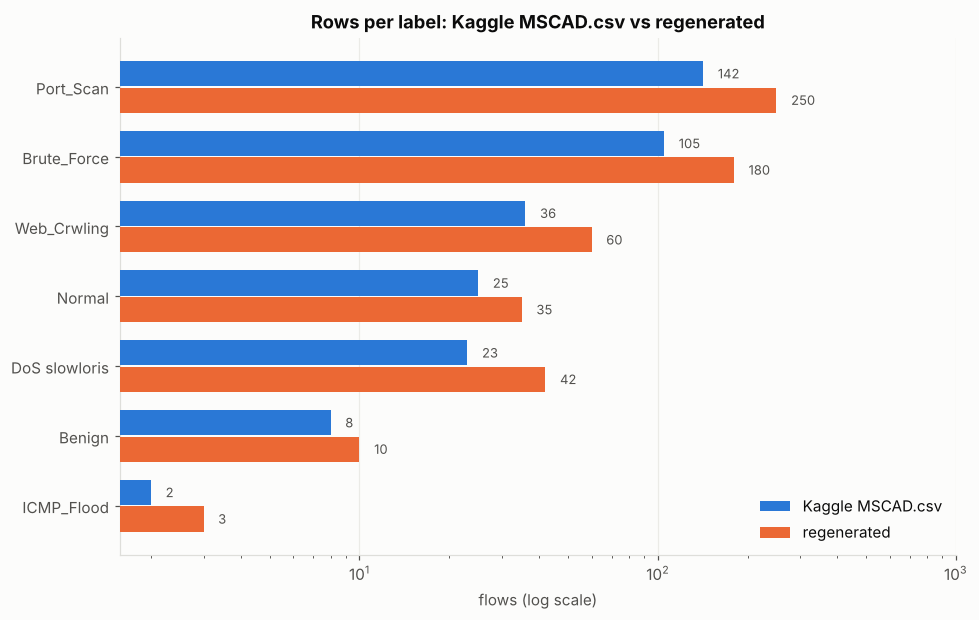

saved /tmp/claude-0/-home-user-MSCAD2022/432fd689-59cc-55c9-96b0-ca4abc48ef75/scratchpad/final/out/notebook_test/metrics/fig2_match_per_label.png


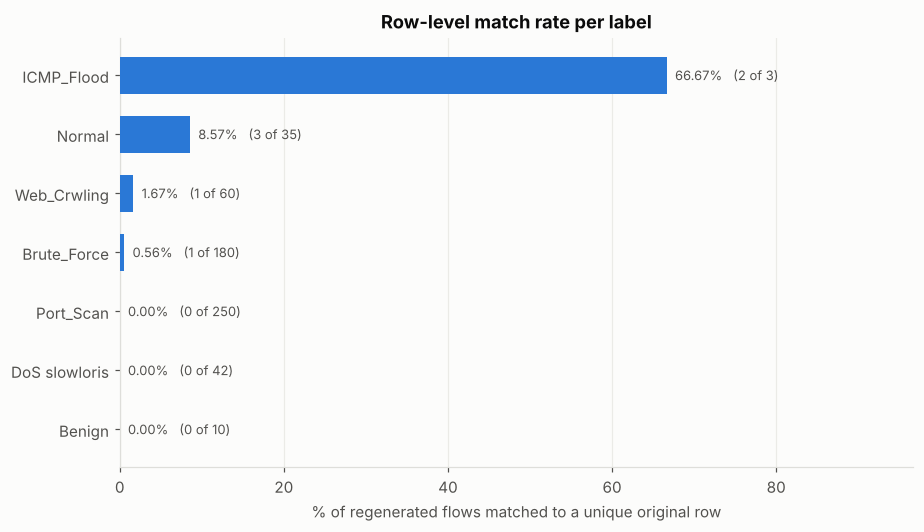

saved /tmp/claude-0/-home-user-MSCAD2022/432fd689-59cc-55c9-96b0-ca4abc48ef75/scratchpad/final/out/notebook_test/metrics/fig3_ks_heatmap.png


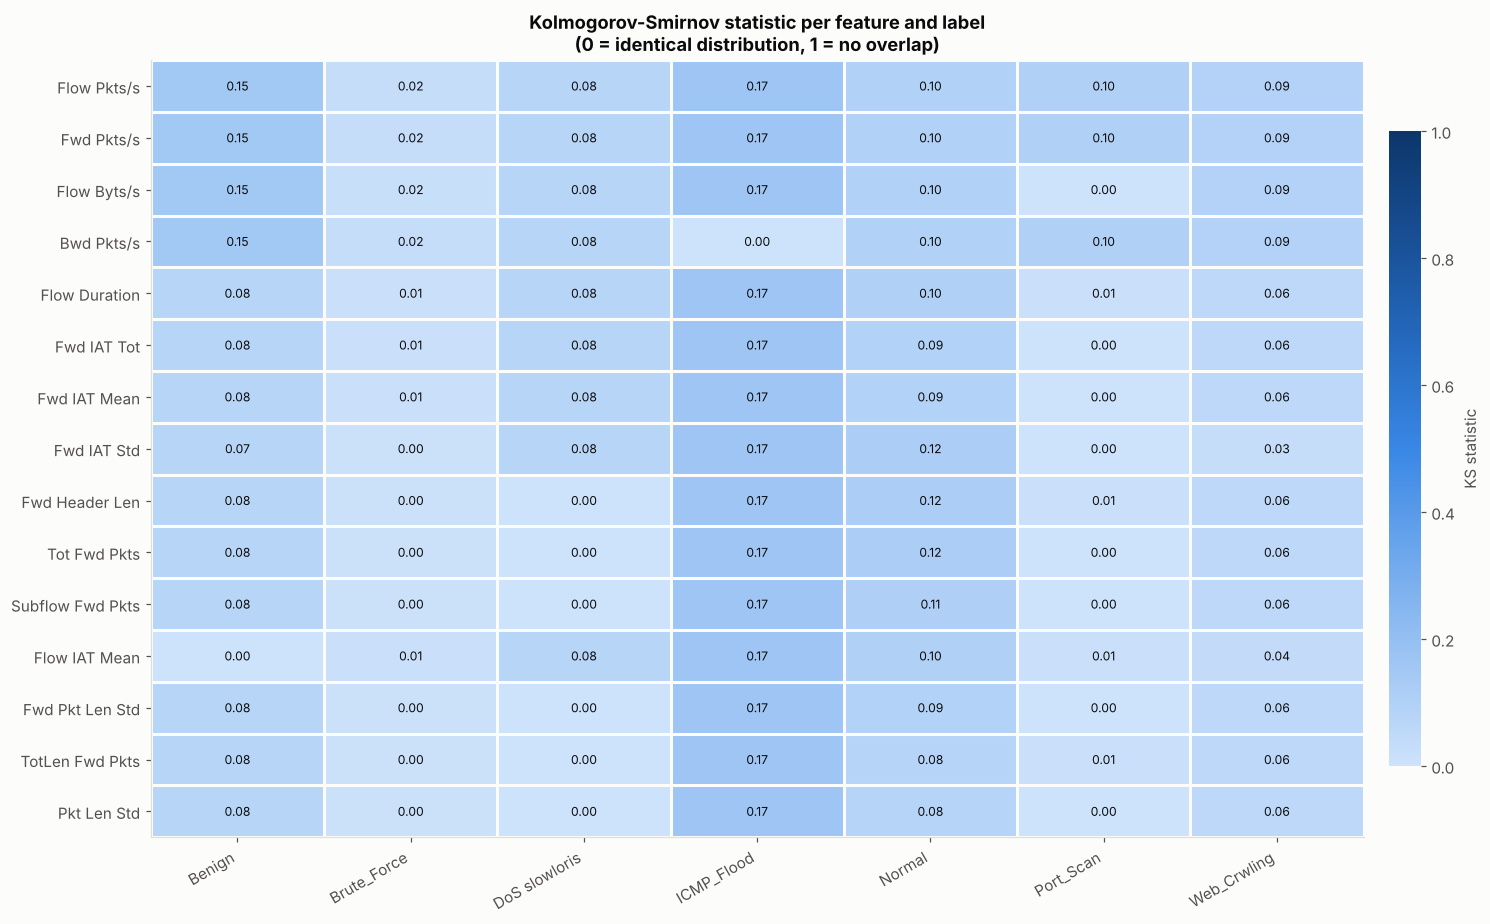


3 figure(s) written to /tmp/claude-0/-home-user-MSCAD2022/432fd689-59cc-55c9-96b0-ca4abc48ef75/scratchpad/final/out/notebook_test/metrics


In [10]:
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

%matplotlib inline

SURFACE = "#fcfcfb"
INK, INK2, INK3 = "#0b0b0b", "#52514e", "#8a8984"
C_KAGGLE, C_REGEN = "#2a78d6", "#eb6834"
BLUE_RAMP = ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf",
             "#184f95", "#0d366b"]
SEQ = LinearSegmentedColormap.from_list("mscad_blue", BLUE_RAMP)

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE, "text.color": INK,
    "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "axes.edgecolor": "#dededa", "grid.color": "#ebebe7",
    "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold",
    "axes.spines.top": False, "axes.spines.right": False,
    "figure.dpi": 110, "savefig.dpi": 160, "savefig.bbox": "tight",
})
PNGS = []


def save(fig, name):
    p = os.path.join(METRICS_DIR, name)
    fig.savefig(p)
    PNGS.append(p)
    print("saved %s" % p)


# ---------------------------------------------- 1. rows per label
d = T72.copy().sort_values("Kaggle", ascending=True)
y = np.arange(len(d))
h = 0.38
fig, ax = plt.subplots(figsize=(9, max(3.0, 0.62 * len(d) + 1.4)))
ax.barh(y + h / 2, d["Kaggle"].clip(lower=0.9), height=h - 0.02,
        color=C_KAGGLE, label="Kaggle MSCAD.csv", zorder=3)
ax.barh(y - h / 2, d["regenerated"].clip(lower=0.9), height=h - 0.02,
        color=C_REGEN, label="regenerated", zorder=3)
for i, (k, r) in enumerate(zip(d["Kaggle"], d["regenerated"])):
    ax.text(max(k, 0.9) * 1.12, i + h / 2, "{:,}".format(int(k)),
            va="center", ha="left", fontsize=8.5, color=INK2)
    ax.text(max(r, 0.9) * 1.12, i - h / 2, "{:,}".format(int(r)),
            va="center", ha="left", fontsize=8.5, color=INK2)
ax.set_xscale("log")
ax.set_yticks(y)
ax.set_yticklabels(d["label"])
ax.set_xlabel("flows (log scale)")
ax.set_title("Rows per label: Kaggle MSCAD.csv vs regenerated")
ax.xaxis.grid(True, zorder=0)
ax.set_axisbelow(True)
ax.legend(frameon=False, loc="lower right")
ax.set_xlim(right=max(d[["Kaggle", "regenerated"]].to_numpy().max() * 4, 10))
fig.tight_layout()
save(fig, "fig1_rows_per_label.png")
plt.show()

# ---------------------------------------------- 2. match % per label
if T75 is not None and len(T75):
    d2 = T75.sort_values("%", ascending=True)
    fig, ax = plt.subplots(figsize=(8.5, max(2.8, 0.52 * len(d2) + 1.3)))
    ax.barh(d2["my label"], d2["%"], color=C_KAGGLE, height=0.62, zorder=3)
    for i, (p, m, n) in enumerate(zip(d2["%"], d2["matched"], d2["rows"])):
        ax.text(p + max(d2["%"].max(), 1) * 0.015, i,
                "%.2f%%   (%s of %s)" % (p, "{:,}".format(int(m)),
                                         "{:,}".format(int(n))),
                va="center", ha="left", fontsize=8.5, color=INK2)
    ax.set_xlabel("% of regenerated flows matched to a unique original row")
    ax.set_title("Row-level match rate per label")
    ax.set_xlim(0, max(d2["%"].max() * 1.45, 1))
    ax.xaxis.grid(True, zorder=0)
    ax.set_axisbelow(True)
    fig.tight_layout()
    save(fig, "fig2_match_per_label.png")
    plt.show()
else:
    print("no match table -- figure 2 skipped")

# ---------------------------------------------- 3. KS heatmap
if per_label and OVERALL_KS:
    top_feats = [f for f, _v in OVERALL_KS[:15]]
    labs = list(per_label.keys())
    M = np.full((len(top_feats), len(labs)), np.nan)
    for j, lab in enumerate(labs):
        by_feat = {d["feature"]: d["ks"] for d in per_label[lab]}
        for i, f in enumerate(top_feats):
            v = by_feat.get(f, np.nan)
            M[i, j] = v if v == v else np.nan
    fig, ax = plt.subplots(figsize=(1.35 * len(labs) + 4.2,
                                    0.42 * len(top_feats) + 2.2))
    im = ax.imshow(M, cmap=SEQ, vmin=0, vmax=1, aspect="auto")
    ax.set_xticks(np.arange(len(labs)))
    ax.set_xticklabels(labs, rotation=30, ha="right")
    ax.set_yticks(np.arange(len(top_feats)))
    ax.set_yticklabels(top_feats)
    ax.set_title("Kolmogorov-Smirnov statistic per feature and label\n"
                 "(0 = identical distribution, 1 = no overlap)")
    for i in range(len(top_feats)):
        for j in range(len(labs)):
            if M[i, j] == M[i, j]:
                ax.text(j, i, "%.2f" % M[i, j], ha="center", va="center",
                        fontsize=8,
                        color="#ffffff" if M[i, j] > 0.55 else INK)
    ax.set_xticks(np.arange(-0.5, len(labs), 1), minor=True)
    ax.set_yticks(np.arange(-0.5, len(top_feats), 1), minor=True)
    ax.grid(which="minor", color=SURFACE, linewidth=2)
    ax.tick_params(which="minor", length=0)
    cb = fig.colorbar(im, ax=ax, fraction=0.025, pad=0.02)
    cb.set_label("KS statistic", color=INK2)
    cb.outline.set_visible(False)
    fig.tight_layout()
    save(fig, "fig3_ks_heatmap.png")
    plt.show()
else:
    print("no per-label KS data -- figure 3 skipped")

print("\n%d figure(s) written to %s" % (len(PNGS), METRICS_DIR))

---
## 9. Final outputs (Part 4)

### `MSCAD_consolidated.csv`

```
Src IP, Dst IP, Src Port, Dst Port, Protocol, Timestamp,
<the 66 MSCAD features>, Label, Label_Kaggle, Source_Capture
```

sorted by `Timestamp`. `Label_Kaggle` carries the official Kaggle label where
step 7.5 matched the row to a unique original row, and is empty otherwise.
This is the file for the PrefixSpan and attack-graph stages, because it is the
one that keeps every flow **and** its identifiers.

### `MSCAD_consolidated_ML.csv`

The 66 features + `Label` only: infinite rate features dropped, then identical
feature vectors de-duplicated.

**Both of those steps delete real attack traffic, and not a little of it.** A
port scan is almost entirely single-packet, zero-duration flows, whose
`Flow Byts/s` is `Infinity` — so dropping non-finite rows removes most of the
scan. The cell prints a per-label breakdown of **which step removed how many
rows**, so the cost is visible rather than silent. Two switches in the settings
cell change it without touching anything else:

* `ML_INF_MODE = "cap"` keeps those rows, replacing `±inf` in each rate column
  with that column's finite maximum × `ML_INF_CAP_FACTOR`. The result is
  guaranteed finite, which is what the LSTM/CNN scalers need.
* `ML_DROP_DUPLICATE_FEATURES = False` keeps genuinely repeated flood and scan
  flows.

The defaults reproduce the existing files exactly.

In [11]:
CONSOLIDATED = os.path.join(OUTPUT_DIR, "MSCAD_consolidated.csv")
ML_FILE = os.path.join(OUTPUT_DIR, "MSCAD_consolidated_ML.csv")

df = ALL.sort_values("Timestamp", kind="mergesort").reset_index(drop=True)
cons_cols = [c for c in (list(IDENTIFIER_COLUMNS) + list(FEATURES)
                         + [LABEL_COLUMN, "Label_Kaggle", "Source_Capture"])
             if c in df.columns]
df[cons_cols].to_csv(CONSOLIDATED, index=False)

print("wrote %s" % CONSOLIDATED)
print("  shape : %s rows x %d columns"
      % ("{:,}".format(len(df)), len(cons_cols)))
lc = df[LABEL_COLUMN].astype(str).value_counts()
print("  labels:")
for k, v in lc.items():
    print("      %-18s %10s" % (k, "{:,}".format(int(v))))
print("  Label_Kaggle present : %s"
      % "{:,}".format(int((df["Label_Kaggle"].astype(str) != "").sum())))
print("  per capture:")
for k, v in df["Source_Capture"].value_counts().items():
    print("      %-10s %10s" % (k, "{:,}".format(int(v))))

# ------------------------------------------------------------- the ML file
print("\nbuilding the ML file ...")
ml = df[[c for c in FEATURES if c in df.columns] + [LABEL_COLUMN]].copy()
fcols = list(ml.columns[:-1])
for c in fcols:
    if ml[c].dtype == object:
        ml[c] = pd.to_numeric(
            ml[c].replace({"Infinity": np.inf, "-Infinity": -np.inf,
                           "inf": np.inf, "-inf": -np.inf}), errors="coerce")

inf_mode = str(CFG.ML_INF_MODE).lower()
print("  inf handling                            : %s" % inf_mode)
n0 = len(ml)
n_inf_cells, capped = 0, {}
if inf_mode == "cap":
    for c in fcols:
        col = ml[c]
        isinf = np.isinf(col.to_numpy(dtype="float64", na_value=np.nan))
        k = int(isinf.sum())
        if not k:
            continue
        n_inf_cells += k
        finite_max = col[np.isfinite(
            col.to_numpy(dtype="float64", na_value=np.nan))].max()
        if not np.isfinite(finite_max) or finite_max <= 0:
            finite_max = 1.0
        cap = float(finite_max) * float(CFG.ML_INF_CAP_FACTOR)
        ml.loc[isinf & (col > 0), c] = cap
        ml.loc[isinf & (col < 0), c] = -cap
        capped[c] = {"cells": k, "cap": cap}
    for c, dd in sorted(capped.items()):
        print("      capped %-16s %8s cell(s) at %.6g"
              % (c, "{:,}".format(dd["cells"]), dd["cap"]))

ml[fcols] = ml[fcols].replace([np.inf, -np.inf], np.nan)
bad = ml[fcols].isna().any(axis=1)
print("  rows with inf/NaN in a feature, dropped : %s"
      % "{:,}".format(int(bad.sum())))
lost_inf = ml.loc[bad, LABEL_COLUMN].astype(str).value_counts().to_dict()
ml = ml[~bad]
n1 = len(ml)
before_dedup = ml[LABEL_COLUMN].astype(str).value_counts().to_dict()
if CFG.ML_DROP_DUPLICATE_FEATURES:
    ml = ml.drop_duplicates(subset=fcols)
n2 = len(ml)
print("  identical feature vectors dropped       : %s"
      % "{:,}".format(n1 - n2))
after_dedup = ml[LABEL_COLUMN].astype(str).value_counts().to_dict()
lost_dedup = {k: int(v) - int(after_dedup.get(k, 0))
              for k, v in before_dedup.items()}

ml.to_csv(ML_FILE, index=False)
print("\nwrote %s" % ML_FILE)
print("  shape : %s rows x %d columns"
      % ("{:,}".format(ml.shape[0]), ml.shape[1]))
mlc = ml[LABEL_COLUMN].astype(str).value_counts()
for k, v in mlc.items():
    print("      %-18s %10s" % (k, "{:,}".format(int(v))))

print("\n  what this file costs, per label (each column = rows that step "
      "actually removed):")
ML_LOSS = pd.DataFrame([{
    "label": str(k), "flows in full file": int(v),
    "removed: inf/NaN": int(lost_inf.get(str(k), 0)),
    "removed: duplicate": int(lost_dedup.get(str(k), 0)),
    "rows in ML file": int(mlc.get(str(k), 0)),
    "kept %": round(100.0 * int(mlc.get(str(k), 0)) / int(v), 1) if v else 0.0,
} for k, v in lc.items()])
display(ML_LOSS)
worst = ML_LOSS.sort_values("kept %").head(1)
if len(worst) and float(worst["kept %"].iloc[0]) < 25.0:
    w = worst.iloc[0]
    dom_dup = int(w["removed: duplicate"]) >= int(w["removed: inf/NaN"])
    print("NOTE: '%s' keeps only %.1f%% of its flows. The dominant cause is "
          "%s." % (w["label"], float(w["kept %"]),
                   "de-duplication" if dom_dup
                   else "the non-finite rate features"))
    print("      Set %s in the settings cell to keep those rows."
          % ("ML_DROP_DUPLICATE_FEATURES = False" if dom_dup
             else 'ML_INF_MODE = "cap"'))

ML_LOSS.to_csv(os.path.join(METRICS_DIR, "09_ml_loss_per_label.csv"),
               index=False)
with open(os.path.join(METRICS_DIR, "04_consolidated.json"), "w") as fh:
    json.dump({
        "consolidated_path": CONSOLIDATED,
        "consolidated_shape": [int(len(df)), len(cons_cols)],
        "consolidated_columns": cons_cols,
        "consolidated_labels": {str(k): int(v) for k, v in lc.items()},
        "consolidated_per_capture": {
            str(k): int(v) for k, v in df["Source_Capture"]
            .value_counts().items()},
        "label_kaggle_filled": int((df["Label_Kaggle"].astype(str) != "").sum()),
        "ml_path": ML_FILE, "ml_shape": [int(ml.shape[0]), int(ml.shape[1])],
        "ml_labels": {str(k): int(v) for k, v in mlc.items()},
        "ml_rows_dropped_inf_nan": int(n0 - n1),
        "ml_rows_dropped_duplicate": int(n1 - n2),
        "ml_inf_mode": inf_mode, "ml_inf_cells_capped": int(n_inf_cells),
        "ml_capped_columns": capped,
        "ml_loss_per_label": ML_LOSS.to_dict("records"),
    }, fh, indent=2, default=str)

wrote /tmp/claude-0/-home-user-MSCAD2022/432fd689-59cc-55c9-96b0-ca4abc48ef75/scratchpad/final/out/notebook_test/MSCAD_consolidated.csv
  shape : 580 rows x 75 columns
  labels:
      Port_Scan                 250
      Brute_Force               180
      Web_Crwling                60
      DoS slowloris              42
      Normal                     35
      Benign                     10
      ICMP_Flood                  3
  Label_Kaggle present : 7
  per capture:
      Scan-1            252
      W-B-02            182
      W-B-01             62
      App-01             44
      N-0                35
      App-02              5

building the ML file ...
  inf handling                            : drop
  rows with inf/NaN in a feature, dropped : 368
  identical feature vectors dropped       : 182

wrote /tmp/claude-0/-home-user-MSCAD2022/432fd689-59cc-55c9-96b0-ca4abc48ef75/scratchpad/final/out/notebook_test/MSCAD_consolidated_ML.csv
  shape : 30 rows x 67 columns
      Normal      

,label,flows in full file,removed: inf/NaN,removed: duplicate,rows in ML file,kept %
0,Port_Scan,250,230,18,2,0.8
1,Brute_Force,180,90,83,7,3.9
2,Web_Crwling,60,30,24,6,10.0
3,DoS slowloris,42,0,40,2,4.8
4,Normal,35,13,13,9,25.7
5,Benign,10,5,4,1,10.0
6,ICMP_Flood,3,0,0,3,100.0


NOTE: 'Port_Scan' keeps only 0.8% of its flows. The dominant cause is the non-finite rate features.
      Set ML_INF_MODE = "cap" in the settings cell to keep those rows.


---
## 9b. Diff against the files already in the project folder

The safety gate. While `WRITE_TO_MAIN = False`, the files just written live in
`notebook_test\` and the originals are untouched. This cell compares them:

* shape (rows x columns);
* column names **and order**;
* label counts;
* a full value-level equality check on the consolidated CSVs, done on the
  re-read text of both files so that float formatting is compared exactly as
  stored.

If every row below says `SAME`, the notebook reproduces your existing outputs
and you can set `WRITE_TO_MAIN = True` in the settings cell and re-run. If
anything differs, the cell prints what and where.

When `WRITE_TO_MAIN = True` this cell has nothing to compare against (it would
be diffing the files against themselves) and says so.

In [12]:
def read_csv_text(path):
    """Re-read as text so float formatting is compared exactly as stored."""
    return pd.read_csv(path, dtype=str, keep_default_na=False,
                       low_memory=False)


def diff_pair(new_path, old_path, name):
    rows = []

    def add(check, verdict, detail=""):
        rows.append({"file": name, "check": check, "result": verdict,
                     "detail": detail})

    if not os.path.isfile(old_path):
        add("exists", "NO BASELINE", "no existing %s to compare against"
            % os.path.basename(old_path))
        return rows
    a, b = read_csv_text(new_path), read_csv_text(old_path)
    add("shape", "SAME" if a.shape == b.shape else "DIFFERENT",
        "new %s x %d vs existing %s x %d"
        % ("{:,}".format(a.shape[0]), a.shape[1],
           "{:,}".format(b.shape[0]), b.shape[1]))

    if list(a.columns) == list(b.columns):
        add("columns + order", "SAME", "%d columns" % a.shape[1])
    else:
        only_new = [c for c in a.columns if c not in b.columns]
        only_old = [c for c in b.columns if c not in a.columns]
        if not only_new and not only_old:
            add("columns + order", "DIFFERENT", "same names, different order")
        else:
            add("columns + order", "DIFFERENT",
                "only new: %s | only existing: %s"
                % (only_new or "-", only_old or "-"))

    if "Label" in a.columns and "Label" in b.columns:
        ca = a["Label"].value_counts().sort_index()
        cb = b["Label"].value_counts().sort_index()
        if ca.equals(cb):
            add("label counts", "SAME", "%d labels" % len(ca))
        else:
            allk = sorted(set(ca.index) | set(cb.index))
            add("label counts", "DIFFERENT",
                "; ".join("%s new=%d existing=%d"
                          % (k, int(ca.get(k, 0)), int(cb.get(k, 0)))
                          for k in allk
                          if int(ca.get(k, 0)) != int(cb.get(k, 0))))

    if a.shape == b.shape and list(a.columns) == list(b.columns):
        ne = (a.to_numpy() != b.to_numpy())
        n_cells = int(ne.sum())
        if not n_cells:
            add("every value", "SAME", "all %s cells identical"
                % "{:,}".format(a.size))
        else:
            bad_cols = {a.columns[j]: int(ne[:, j].sum())
                        for j in range(a.shape[1]) if ne[:, j].any()}
            worst = sorted(bad_cols.items(), key=lambda kv: -kv[1])[:6]
            add("every value", "DIFFERENT",
                "%s of %s cells differ, in %d column(s); worst: %s"
                % ("{:,}".format(n_cells), "{:,}".format(a.size),
                   len(bad_cols),
                   ", ".join("%s (%s)" % (c, "{:,}".format(n))
                             for c, n in worst)))
            first = int(np.flatnonzero(ne.any(axis=1))[0])
            add("first differing row", "row %d" % first,
                "; ".join("%s: new=%r existing=%r"
                          % (c, a.iloc[first][c], b.iloc[first][c])
                          for c in bad_cols)[:400])
    else:
        add("every value", "NOT COMPARED",
            "shape or columns differ, so a cell-by-cell diff is meaningless")
    return rows


if WRITE_TO_MAIN:
    print("WRITE_TO_MAIN = True -- this run wrote straight into")
    print("  %s" % OUTPUT_DIR)
    print("so there is no separate baseline to diff against.")
    print("\nRe-run with WRITE_TO_MAIN = False if you want the comparison.")
    DIFF = pd.DataFrame(columns=["file", "check", "result", "detail"])
else:
    rows = []
    rows += diff_pair(CONSOLIDATED,
                      os.path.join(PROJECT_DIR, "MSCAD_consolidated.csv"),
                      "MSCAD_consolidated.csv")
    rows += diff_pair(ML_FILE,
                      os.path.join(PROJECT_DIR, "MSCAD_consolidated_ML.csv"),
                      "MSCAD_consolidated_ML.csv")
    DIFF = pd.DataFrame(rows)
    with pd.option_context("display.max_colwidth", 150, "display.width", 250):
        display(DIFF)

    verdicts = set(DIFF["result"]) - {"SAME"}
    print()
    if not verdicts:
        print("=" * 74)
        print("IDENTICAL: the notebook reproduces both existing files exactly.")
        print("Set WRITE_TO_MAIN = True in the settings cell and re-run to")
        print("write into %s" % PROJECT_DIR)
        print("=" * 74)
    elif verdicts == {"NO BASELINE"}:
        print("No existing files to compare against -- nothing was "
              "overwritten.")
    else:
        print("=" * 74)
        print("DIFFERENCES FOUND -- read the detail column above before")
        print("setting WRITE_TO_MAIN = True. Your existing files are intact.")
        print("=" * 74)

DIFF.to_csv(os.path.join(METRICS_DIR, "09b_diff_vs_existing.csv"), index=False)

,file,check,result,detail
0,MSCAD_consolidated.csv,shape,SAME,new 580 x 75 vs existing 580 x 75
1,MSCAD_consolidated.csv,columns + order,SAME,75 columns
2,MSCAD_consolidated.csv,label counts,SAME,7 labels
3,MSCAD_consolidated.csv,every value,SAME,"all 43,500 cells identical"
4,MSCAD_consolidated_ML.csv,shape,SAME,new 30 x 67 vs existing 30 x 67
5,MSCAD_consolidated_ML.csv,columns + order,SAME,67 columns
6,MSCAD_consolidated_ML.csv,label counts,SAME,7 labels
7,MSCAD_consolidated_ML.csv,every value,SAME,"all 2,010 cells identical"



IDENTICAL: the notebook reproduces both existing files exactly.
Set WRITE_TO_MAIN = True in the settings cell and re-run to
write into /tmp/claude-0/-home-user-MSCAD2022/432fd689-59cc-55c9-96b0-ca4abc48ef75/scratchpad/final/out


---
## 10. Summary

Every output file with its size and row count, then a tick/cross list of all
the checks this run performed. A cross is not necessarily a defect -- read the
note beside it.

In [13]:
print("=" * 86)
print("OUTPUT FILES")
print("=" * 86)


def count_rows(path):
    try:
        with open(path, "rb") as fh:
            return max(0, sum(1 for _ in fh) - 1)
    except Exception:
        return None


wanted = ([CONSOLIDATED, ML_FILE]
          + [raw_csv_path(k, write=RUN_EXTRACTION) for k, _l, _d in CAPTURES]
          + [os.path.join(LABELLED_DIR, "%s_labelled.csv" % k)
             for k, _l, _d in CAPTURES]
          + sorted(os.path.join(METRICS_DIR, f)
                   for f in os.listdir(METRICS_DIR)))
seen, files = set(), []
for p in wanted:
    if p in seen or not os.path.isfile(p):
        continue
    seen.add(p)
    sz = os.path.getsize(p)
    files.append({
        "file": os.path.relpath(p, OUTPUT_DIR)
        if p.startswith(OUTPUT_DIR) else p,
        "size": ("%.1f MB" % (sz / 1048576.0) if sz >= 1048576
                 else "%.0f KB" % (sz / 1024.0)),
        "rows": (count_rows(p) if p.lower().endswith(".csv") else "-"),
    })
FILES = pd.DataFrame(files)
with pd.option_context("display.max_colwidth", 70, "display.max_rows", 200):
    display(FILES)

print("=" * 86)
print("CHECKS")
print("=" * 86)
checks = []


def chk(name, ok, note=""):
    checks.append({"check": name, "ok": bool(ok),
                   "": "PASS" if ok else "SEE NOTE", "note": note})


pkt_rows = [r for r in VERIFY if r["ipv4_in_flows"] is not None]
indep = [r for r in pkt_rows
         if r.get("tshark_ipv4") is not None or r.get("second_ipv4") is not None]
pkt_ok = all(r.get(k) in (None, r["ipv4_in_flows"])
             for r in pkt_rows
             for k in ("tshark_ipv4", "second_ipv4", "ipv4_parsed"))
chk("packet completeness: flow totals equal the independent counts",
    pkt_ok and bool(indep),
    ("%d/%d captures had at least one independent count"
     % (len(indep), len(pkt_rows)))
    if indep else "no independent count available (no PCAPs, no tshark)")
chk("no flow written twice (5-tuple + start timestamp)",
    all(r["duplicate_flows"] == 0 for r in VERIFY))
chk("no NaN in any feature", all(r["nan_cells"] == 0 for r in VERIFY))
chk("no negative feature values (Init Win Byts = -1 exempt)",
    all(r["negative_cells"] == 0 for r in VERIFY))
chk("no min > max inconsistency",
    all(r["minmax_violation_total"] == 0 for r in VERIFY))
chk("all ports and protocol values valid",
    all(r["invalid_ports"] == 0 and r["invalid_protocol"] == 0
        for r in VERIFY))
chk("recomputed labels match the ones stored in raw\\",
    not relabel_mismatches,
    "mismatches: %s" % relabel_mismatches if relabel_mismatches else "")
chk("ICMP kept as its own flows (Protocol 1, Port 0)",
    any("1" in r["protocol_counts"] or 1 in r["protocol_counts"]
        for r in VERIFY),
    "App-02's flood would be lost without this")
chk("66 feature names and order identical to the original",
    COMPARE["schema"]["same_names_and_order"],
    "missing: %s | extra: %s"
    % (COMPARE["schema"]["missing_in_regenerated"] or "-",
       COMPARE["schema"]["extra_in_regenerated"] or "-")
    if not COMPARE["schema"]["same_names_and_order"] else "")
chk("every original column mapped to a CICFlowMeter feature",
    not COMPARE["schema"]["unmapped_original_columns"],
    "unmapped: %s" % COMPARE["schema"]["unmapped_original_columns"]
    if COMPARE["schema"]["unmapped_original_columns"] else "")
chk("time features in microseconds in both files (no 10^6 mismatch)",
    not bad_units,
    "%d label/feature pair(s) flagged" % len(bad_units) if bad_units else "")
agree = COMPARE.get("label_agreement_matched")
chk("label agreement on matched rows", bool(agree) and agree["pct"] >= 99.0,
    ("%d/%d (%.2f%%)" % (agree["agree"], agree["total"], agree["pct"]))
    if agree else "no rows matched, so there is nothing to agree about")
infs = sum(r["inf_cells"] for r in VERIFY)
chk("inf confined to the rate features of zero-duration flows", True,
    "%s inf cells, all in Flow Byts/s / Flow Pkts/s / Fwd Pkts/s / "
    "Bwd Pkts/s -- normal CICFlowMeter behaviour"
    % "{:,}".format(infs))
dups = sum(r["duplicate_feature_rows"] for r in VERIFY)
chk("identical feature rows counted, not dropped, in the full file", True,
    "%s rows share a feature vector -- expected in floods, scans and brute "
    "force" % "{:,}".format(dups))
if not WRITE_TO_MAIN and len(DIFF):
    bad = set(DIFF["result"]) - {"SAME"}
    chk("reproduces the existing MSCAD_consolidated*.csv exactly",
        not bad,
        "" if not bad else "see the step 9b table")

CHECKS = pd.DataFrame(checks)[["", "check", "note"]]
for _i, row in CHECKS.iterrows():
    print("%s  %-62s %s"
          % ("[v]" if row[""] == "PASS" else "[x]", row["check"], row["note"]))

n_pass = sum(1 for c in checks if c["ok"])
print("\n%d of %d checks passed." % (n_pass, len(checks)))
print("\nwrote into: %s" % OUTPUT_DIR)
if not WRITE_TO_MAIN:
    print("This was a TEST run -- your existing files in")
    print("  %s" % PROJECT_DIR)
    print("were not modified. Set WRITE_TO_MAIN = True to write there.")

FILES.to_csv(os.path.join(METRICS_DIR, "10_output_files.csv"), index=False)
CHECKS.to_csv(os.path.join(METRICS_DIR, "10_checks.csv"), index=False)
print("\ndone.")

OUTPUT FILES


,file,size,rows
0,MSCAD_consolidated.csv,178 KB,580
1,MSCAD_consolidated_ML.csv,10 KB,30
2,/tmp/claude-0/-home-user-MSCAD2022/432fd689-59cc-55c9-96b0-ca4abc4...,12 KB,35
3,/tmp/claude-0/-home-user-MSCAD2022/432fd689-59cc-55c9-96b0-ca4abc4...,61 KB,252
4,/tmp/claude-0/-home-user-MSCAD2022/432fd689-59cc-55c9-96b0-ca4abc4...,17 KB,44
5,/tmp/claude-0/-home-user-MSCAD2022/432fd689-59cc-55c9-96b0-ca4abc4...,3 KB,5
6,/tmp/claude-0/-home-user-MSCAD2022/432fd689-59cc-55c9-96b0-ca4abc4...,20 KB,62
7,/tmp/claude-0/-home-user-MSCAD2022/432fd689-59cc-55c9-96b0-ca4abc4...,58 KB,182
8,labelled/N-0_labelled.csv,12 KB,35
9,labelled/Scan-1_labelled.csv,63 KB,252


CHECKS
[v]  packet completeness: flow totals equal the independent counts  6/6 captures had at least one independent count
[v]  no flow written twice (5-tuple + start timestamp)              
[v]  no NaN in any feature                                          
[v]  no negative feature values (Init Win Byts = -1 exempt)         
[v]  no min > max inconsistency                                     
[v]  all ports and protocol values valid                            
[v]  recomputed labels match the ones stored in raw\                
[v]  ICMP kept as its own flows (Protocol 1, Port 0)                App-02's flood would be lost without this
[v]  66 feature names and order identical to the original           
[v]  every original column mapped to a CICFlowMeter feature         
[v]  time features in microseconds in both files (no 10^6 mismatch) 
[v]  label agreement on matched rows                                7/7 (100.00%)
[v]  inf confined to the rate features of zero-duration flows   

---
### Where to go next

* `MSCAD_consolidated.csv` is the file for **PrefixSpan** and the
  **attack-state graph**: group by `(Src IP, Dst IP)`, sort by `Timestamp`, and
  the `Label` column becomes the item sequence per host pair.
* `MSCAD_consolidated_ML.csv` is for the **RF / XGBoost / LSTM / CNN** stages.
  Read the per-label loss table in step 9 before you trust its class balance,
  and consider `ML_INF_MODE = "cap"`.
* `metrics\03_comparison.json` holds every number from step 7 in
  machine-readable form, including the full per-feature KS table, if you want
  to put specific figures in the thesis text.